
# Task 1:  Introduction, History, Pipelines & Tokenizer

## 1.1 Install and first pipeline

In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import (pipeline,AutoTokenizer,AutoModel,AutoModelForSequenceClassification)
torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("\nLibraries imported successfully.")

NumPy version: 2.1.3
Pandas version: 2.2.3
PyTorch version: 2.11.0+cu130
CUDA available: True

Libraries imported successfully.


In [3]:
model_name = "distilbert-base-uncased-finetuned-sst-2-english"

sentiment_pipeline = pipeline("sentiment-analysis",model=model_name,device=-1)

sentences = [
    "I absolutely love learning deep learning.",
    "This movie was boring and disappointing.",
    "The food was excellent and delicious.",
    "I do not think this product is good.",
    "The movie was not bad, and I enjoyed it."]

results = sentiment_pipeline(sentences)

for i, (sentence, result) in enumerate(zip(sentences, results), start=1):
    print(f"Sentence {i}: {sentence}")
    print("Predicted label:", result["label"])
    print("Confidence score:", round(result["score"], 4))
    print("-" * 70)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Sentence 1: I absolutely love learning deep learning.
Predicted label: POSITIVE
Confidence score: 0.9998
----------------------------------------------------------------------
Sentence 2: This movie was boring and disappointing.
Predicted label: NEGATIVE
Confidence score: 0.9998
----------------------------------------------------------------------
Sentence 3: The food was excellent and delicious.
Predicted label: POSITIVE
Confidence score: 0.9999
----------------------------------------------------------------------
Sentence 4: I do not think this product is good.
Predicted label: NEGATIVE
Confidence score: 0.9998
----------------------------------------------------------------------
Sentence 5: The movie was not bad, and I enjoyed it.
Predicted label: POSITIVE
Confidence score: 0.9999
----------------------------------------------------------------------


## Task 1.3 — Impact and disadvantages

### Impact
- Machine translation
- Search engines and information retrieval
- Chat assistants and question answering
- Code completion and code generation
- Image understanding and generation
- Protein structure prediction

### Disadvantages
- Standard full self-attention has quadratic cost in sequence length.
- Models have context-window limits.
- Large models can require substantial memory and computing resources.
- Training powerful models can require large datasets.
- Generative models can produce hallucinations or incorrect facts.
- Their internal behaviour can be difficult to interpret.


## Task 1.4 — Tokenizer in action

## Load the tokenizer

In [4]:
tokenizer = AutoTokenizer.from_pretrained(model_name)
text = "Transformers are surprisingly easy to understand."

tokens = tokenizer.tokenize(text)
encoded = tokenizer(text,return_tensors="pt")

print("Original text:")
print(text)
print("\nTokens:")
print(tokens)
print("\nInput IDs:")
print(encoded["input_ids"])
print("\nAttention mask:")
print(encoded["attention_mask"])
print("\nDecoded text:")
print(tokenizer.decode(encoded["input_ids"][0]))


Original text:
Transformers are surprisingly easy to understand.

Tokens:
['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']

Input IDs:
tensor([[  101, 19081,  2024, 10889,  3733,  2000,  3305,  1012,   102]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1]])

Decoded text:
[CLS] transformers are surprisingly easy to understand. [SEP]


In [5]:
rare_word = "antidisestablishmentarianism"

print("Original word:", rare_word)
print("Subword tokens:", tokenizer.tokenize(rare_word))

rare_encoded = tokenizer(rare_word)

print("Input IDs:", rare_encoded["input_ids"])
print("Decoded tokens:", tokenizer.convert_ids_to_tokens(rare_encoded["input_ids"]))


Original word: antidisestablishmentarianism
Subword tokens: ['anti', '##dis', '##est', '##ab', '##lish', '##ment', '##arian', '##ism']
Input IDs: [101, 3424, 10521, 4355, 7875, 13602, 3672, 12199, 2964, 102]
Decoded tokens: ['[CLS]', 'anti', '##dis', '##est', '##ab', '##lish', '##ment', '##arian', '##ism', '[SEP]']


## Task 1.5 — Batching and padding

In [6]:
sentences_batch = [
    "Transformers learn relationships between tokens.",
    "Deep learning models use attention."
]
batch = tokenizer(sentences_batch,padding=True,return_tensors="pt")

print("Input IDs:")
print(batch["input_ids"])
print("\nAttention mask:")
print(batch["attention_mask"])

print("\nDecoded batch:")
for ids in batch["input_ids"]:
    print(tokenizer.decode(ids))

print("\nBatch shape:", tuple(batch["input_ids"].shape))


Input IDs:
tensor([[  101, 19081,  4553,  6550,  2090, 19204,  2015,  1012,   102],
        [  101,  2784,  4083,  4275,  2224,  3086,  1012,   102,     0]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 0]])

Decoded batch:
[CLS] transformers learn relationships between tokens. [SEP]
[CLS] deep learning models use attention. [SEP] [PAD]

Batch shape: (2, 9)


## Task 1.6 — Model anatomy at a glance

In [7]:
classification_model = AutoModelForSequenceClassification.from_pretrained(
    model_name
)

classification_model.eval()
config = classification_model.config

print("Model ID:", model_name)
print("\nModel configuration:")
print(config)

print("\nKey architecture values:")
print("Number of layers:", config.n_layers)
print("Number of attention heads:", config.n_heads)
print("Hidden size:", config.dim)
print("Vocabulary size:", config.vocab_size)
print("Maximum position embeddings:", config.max_position_embeddings)

total_parameters = sum(parameter.numel()for parameter in classification_model.parameters())
trainable_parameters = sum(parameter.numel()for parameter in classification_model.parameters()if parameter.requires_grad)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model ID: distilbert-base-uncased-finetuned-sst-2-english

Model configuration:
DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForSequenceClassification"
  ],
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "eos_token_id": null,
  "finetuning_task": "sst-2",
  "hidden_dim": 3072,
  "id2label": {
    "0": "NEGATIVE",
    "1": "POSITIVE"
  },
  "initializer_range": 0.02,
  "label2id": {
    "NEGATIVE": 0,
    "POSITIVE": 1
  },
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "output_past": true,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "tie_word_embeddings": true,
  "transformers_version": "5.20.2",
  "vocab_size": 30522
}


Key architecture values:
Number of layers: 6
Number of attention heads: 12
Hidden size: 768
Vocabulary size: 30522
Maximum position emb

In [8]:
print("\nTotal parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")



Total parameters: 66,955,010
Trainable parameters: 66,955,010


## Create the architecture summary table

In [9]:
architecture_summary = pd.DataFrame({
    "Property": [
        "Model ID",
        "Architecture",
        "Number of Transformer layers",
        "Attention heads per layer",
        "Hidden size",
        "Vocabulary size",
        "Maximum position embeddings",
        "Total parameters"
    ],
    "Value": [
        model_name,
        "DistilBERT sequence classification",
        config.n_layers,
        config.n_heads,
        config.dim,
        config.vocab_size,
        config.max_position_embeddings,
        f"{total_parameters:,}"
    ]
})

display(architecture_summary)

,Property,Value
0,Model ID,distilbert-base-uncased-finetuned-sst-2-english
1,Architecture,DistilBERT sequence classification
2,Number of Transformer layers,6
3,Attention heads per layer,12
4,Hidden size,768
5,Vocabulary size,30522
6,Maximum position embeddings,512
7,Total parameters,"66,955,010"



# Task 2: Self-Attention and Scaled Dot-Product Attention


### 2.1 Self-Attention Idea

Self-attention allows every token in a sequence to gather information from other tokens. Each token is projected into three vectors: Query (Q), Key (K) and Value (V). The Query represents what a token is looking for, the Key represents what it offers for matching, and the Value contains the information that can be passed to other tokens. Similarity between Queries and Keys determines the attention weights, which are used to calculate weighted sums of Values. Unlike an RNN, standard self-attention can process all token positions in parallel during a forward pass.


## Import libraries and create sample input

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
X = np.random.randn(4, 8)
d_model = 8
Wq = np.random.randn(8, 8)
Wk = np.random.randn(8, 8)
Wv = np.random.randn(8, 8)

Q = X @ Wq
K = X @ Wk
V = X @ Wv

print("Input X shape:", X.shape)
print("Wq shape:", Wq.shape)
print("Wk shape:", Wk.shape)
print("Wv shape:", Wv.shape)
print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

Input X shape: (4, 8)
Wq shape: (8, 8)
Wk shape: (8, 8)
Wv shape: (8, 8)
Q shape: (4, 8)
K shape: (4, 8)
V shape: (4, 8)


In [11]:
def softmax(x, axis=-1):
    x = np.asarray(x, dtype=np.float64)
    x_max = np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x - x_max)

    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)
test_scores = np.array([1.0, 2.0, 3.0])
test_probabilities = softmax(test_scores)

print("Input scores:", test_scores)
print("Softmax probabilities:", test_probabilities)
print("Probability sum:", test_probabilities.sum())

Input scores: [1. 2. 3.]
Softmax probabilities: [0.09003057 0.24472847 0.66524096]
Probability sum: 0.9999999999999999


## Implement scaled dot-product attention

In [12]:
def scaled_dot_product_attention(Q, K, V):
    d_k = K.shape[-1]
    scores = Q @ K.T
    scaled_scores = scores / np.sqrt(d_k)
    attention_weights = softmax(scaled_scores, axis=-1)
    output = attention_weights @ V

    return scores, scaled_scores, attention_weights, output


scores, scaled_scores, attention_weights, output = (scaled_dot_product_attention(Q, K, V))

print("Raw scores shape:", scores.shape)
print("Scaled scores shape:", scaled_scores.shape)
print("Attention weights shape:", attention_weights.shape)
print("Attention output shape:", output.shape)
print("\nRaw scores:\n", scores)
print("\nScaled scores:\n", scaled_scores)
print("\nAttention weights:\n", attention_weights)
print("\nAttention output:\n", output)
print("\nSum of each attention row:")
print(attention_weights.sum(axis=1))

print("\nAll attention rows sum to 1:",np.allclose(attention_weights.sum(axis=1), 1.0))

Raw scores shape: (4, 4)
Scaled scores shape: (4, 4)
Attention weights shape: (4, 4)
Attention output shape: (4, 8)

Raw scores:
 [[-17.60964734  15.61218788  -4.27913667   5.87640441]
 [ 11.07518836 -14.18442623  -3.57801201  20.41186381]
 [ 17.74354529 -10.12141988   2.14860266 -19.31741203]
 [-10.01189547   8.63980881  -2.95595328   0.10487487]]

Scaled scores:
 [[-6.22595052  5.51974196 -1.51290328  2.0776227 ]
 [ 3.9156704  -5.01495199 -1.26501828  7.21668366]
 [ 6.2732906  -3.57846232  0.75964575 -6.82973652]
 [-3.53973959  3.0546337  -1.0450873   0.03707887]]

Attention weights:
 [[7.67109958e-06 9.68159817e-01 8.54492061e-04 3.09780198e-02]
 [3.55291769e-02 4.69964577e-06 1.99820777e-04 9.64266303e-01]
 [9.95930547e-01 5.24405365e-05 4.01498126e-03 2.03075101e-06]
 [1.28230159e-03 9.37324806e-01 1.55383143e-02 4.58545778e-02]]

Attention output:
 [[-0.68939668 -9.494128   -3.80341092 -5.16705409 -0.79426991  2.65945449
  -0.2745543  -2.76803143]
 [-1.53799964 -3.63883052 -1.788

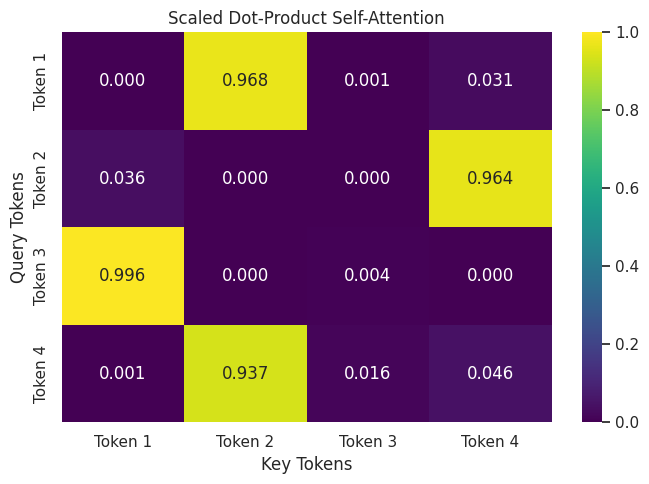

In [13]:
token_labels = ["Token 1", "Token 2", "Token 3", "Token 4"]
plt.figure(figsize=(7, 5))

sns.heatmap(attention_weights,annot=True,fmt=".3f",cmap="viridis",xticklabels=token_labels,yticklabels=token_labels,vmin=0,vmax=1)

plt.title("Scaled Dot-Product Self-Attention")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.tight_layout()
# plt.savefig(
#     "plots/task2_scaled_dot_product_attention.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()

## Task 2.3 — Why divide by \(\sqrt{d_k}\)?


### Why Is Attention Divided by the Square Root of the Key Dimension?

When the feature dimension increases, the magnitude and variance of dot-product scores can increase. Large scores can push softmax toward a saturated distribution where one probability dominates. Dividing by the square root of the key dimension helps control the score scale and can produce more useful gradients during training. We will compare the maximum softmax probability and entropy to observe the effect.


## Run the scaling experiment

In [14]:
np.random.seed(42)

def attention_scaling_experiment(d_k, n_tokens=20):
    Q_test = np.random.randn(n_tokens, d_k)
    K_test = np.random.randn(n_tokens, d_k)

    raw_scores = Q_test @ K_test.T
    results = []

    for scaled in [False, True]:
        if scaled:
            current_scores = raw_scores / np.sqrt(d_k)
            case = "With scaling"
        else:
            current_scores = raw_scores
            case = "Without scaling"

        weights = softmax(current_scores, axis=-1)

        entropy = -np.sum(
            weights * np.log(np.clip(weights, 1e-12, 1.0)),
            axis=-1
        )

        results.append({
            "d_k": d_k,
            "Case": case,
            "Mean maximum probability": weights.max(axis=-1).mean(),
            "Mean entropy": entropy.mean()
        })

    return results
experiment_results = []

for dimension in [4, 256]:
    experiment_results.extend(
        attention_scaling_experiment(dimension)
    )

scaling_df = pd.DataFrame(experiment_results)
display(scaling_df.round(4))


,d_k,Case,Mean maximum probability,Mean entropy
0,4,Without scaling,0.3439,2.1027
1,4,With scaling,0.1713,2.6929
2,256,Without scaling,0.9232,0.1839
3,256,With scaling,0.2176,2.5853


## Plot the scaling results

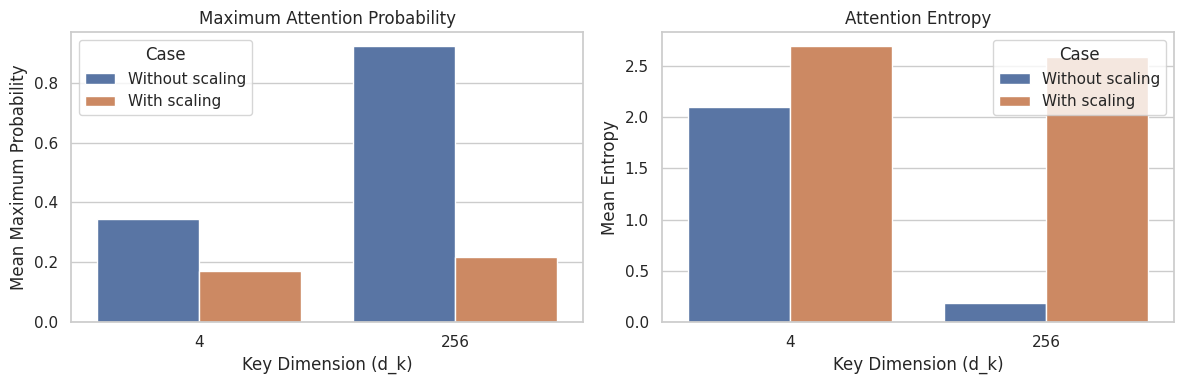

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(
    data=scaling_df,
    x="d_k",
    y="Mean maximum probability",
    hue="Case",
    ax=axes[0]
)
axes[0].set_title("Maximum Attention Probability")
axes[0].set_xlabel("Key Dimension (d_k)")
axes[0].set_ylabel("Mean Maximum Probability")

sns.barplot(data=scaling_df,x="d_k",y="Mean entropy",hue="Case",ax=axes[1])
axes[1].set_title("Attention Entropy")
axes[1].set_xlabel("Key Dimension (d_k)")
axes[1].set_ylabel("Mean Entropy")

plt.tight_layout()
# plt.savefig(
#     "plots/task2_attention_scaling_comparison.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()


## Task 2.4 — Self-attention vs Luong dot attention

In [16]:
np.random.seed(42)
encoder_states = np.random.randn(5, 8)
decoder_state = np.random.randn(8)
luong_scores = encoder_states @ decoder_state
luong_weights = softmax(luong_scores)
context_vector = luong_weights @ encoder_states

print("Encoder states shape:", encoder_states.shape)
print("Decoder state shape:", decoder_state.shape)
print("Luong scores shape:", luong_scores.shape)
print("Luong weights shape:", luong_weights.shape)
print("Context vector shape:", context_vector.shape)
print("\nLuong scores:\n", luong_scores)
print("\nLuong attention weights:\n", luong_weights)
print("\nContext vector:\n", context_vector)
print("\nSum of attention weights:", luong_weights.sum())

Encoder states shape: (5, 8)
Decoder state shape: (8,)
Luong scores shape: (5,)
Luong weights shape: (5,)
Context vector shape: (8,)

Luong scores:
 [ 0.40818741  1.1597874  -3.70553788  2.97027193  2.00301742]

Luong attention weights:
 [0.04755781 0.10084111 0.00077742 0.61648294 0.23434072]

Context vector:
 [-0.36327268 -0.13110175 -0.53344695 -0.03011265 -0.30693492 -0.8433026
 -0.78097616  1.1667187 ]

Sum of attention weights: 0.9999999999999999


## Create the comparison table

In [17]:
comparison = pd.DataFrame({
    "Feature": [
        "Where Q comes from",
        "Where K comes from",
        "Where V comes from",
        "What is attended over",
        "RNN required?",
        "Parallelism",
        "Typical architecture location"
    ],
    "Luong Dot Attention": [
        "Decoder hidden state",
        "Encoder hidden states",
        "Encoder hidden states",
        "Encoder states for a decoder step",
        "In the original seq2seq setup, commonly yes",
        "Attention is computed per decoder step",
        "Encoder-decoder sequence-to-sequence models"
    ],
    "Self-Attention": [
        "Input token representations",
        "Input token representations",
        "Input token representations",
        "Tokens in the same sequence",
        "No",
        "All sequence positions can be processed in parallel",
        "Transformer encoder and decoder blocks"
    ]
})

display(comparison)


,Feature,Luong Dot Attention,Self-Attention
0,Where Q comes from,Decoder hidden state,Input token representations
1,Where K comes from,Encoder hidden states,Input token representations
2,Where V comes from,Encoder hidden states,Input token representations
3,What is attended over,Encoder states for a decoder step,Tokens in the same sequence
4,RNN required?,"In the original seq2seq setup, commonly yes",No
5,Parallelism,Attention is computed per decoder step,All sequence positions can be processed in par...
6,Typical architecture location,Encoder-decoder sequence-to-sequence models,Transformer encoder and decoder blocks


## Task 2.5 — Demonstrate that self-attention is order-blind

## Shuffle the input and compare outputs

In [18]:
_, _, original_weights, original_output = (
    scaled_dot_product_attention(Q, K, V))
permutation = np.array([2, 0, 3, 1])

X_shuffled = X[permutation]
Q_shuffled = X_shuffled @ Wq
K_shuffled = X_shuffled @ Wk
V_shuffled = X_shuffled @ Wv

_, _, shuffled_weights, shuffled_output = (
    scaled_dot_product_attention(
        Q_shuffled,
        K_shuffled,
        V_shuffled
    )
)
expected_shuffled_output = original_output[permutation]

print("Permutation:", permutation)
print("\nOriginal output shape:", original_output.shape)
print("Shuffled output shape:", shuffled_output.shape)

print(
    "\nShuffled output matches permuted original output:",
    np.allclose(shuffled_output, expected_shuffled_output)
)

inverse_permutation = np.argsort(permutation)
restored_output = shuffled_output[inverse_permutation]

print("Restored output matches original output:",np.allclose(restored_output, original_output))


Permutation: [2 0 3 1]

Original output shape: (4, 8)
Shuffled output shape: (4, 8)

Shuffled output matches permuted original output: True
Restored output matches original output: True



### Why Does Self-Attention Need Positional Encoding?

Self-attention calculates relationships between token representations but does not inherently identify their absolute positions. When token rows are shuffled, the corresponding output rows are shuffled in the same order. The demonstration confirms this property for our implementation. Transformers therefore add positional information so the model can distinguish identical words appearing at different positions.


## Task 2.6 — Verify our attention against real DistilBERT

## Load DistilBERT with attention outputs enabled

In [19]:
from transformers import AutoTokenizer, AutoModel

real_model_name = "distilbert-base-uncased-finetuned-sst-2-english"
real_tokenizer = AutoTokenizer.from_pretrained(real_model_name)
real_model = AutoModel.from_pretrained(
    real_model_name,
    attn_implementation="eager"
)

real_model.eval()

print("Model loaded successfully.")
print("Number of layers:", real_model.config.n_layers)
print("Number of heads:", real_model.config.n_heads)
print("Hidden size:", real_model.config.dim)
print("\nFirst Transformer layer:")
print(real_model.transformer.layer[0])

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded successfully.
Number of layers: 6
Number of heads: 12
Hidden size: 768

First Transformer layer:
TransformerBlock(
  (attention): DistilBertSelfAttention(
    (q_lin): Linear(in_features=768, out_features=768, bias=True)
    (k_lin): Linear(in_features=768, out_features=768, bias=True)
    (v_lin): Linear(in_features=768, out_features=768, bias=True)
    (out_lin): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
  (ffn): FFN(
    (dropout): Dropout(p=0.1, inplace=False)
    (lin1): Linear(in_features=768, out_features=3072, bias=True)
    (lin2): Linear(in_features=3072, out_features=768, bias=True)
    (activation): GELUActivation()
  )
  (output_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
)


## Run a sentence through the real model

In [20]:
verification_text = "The animal did not cross the street because it was too tired."

inputs = real_tokenizer(
    verification_text,
    return_tensors="pt"
)

with torch.no_grad():
    outputs = real_model(
        **inputs,
        output_hidden_states=True,
        output_attentions=True
    )

hidden_states = outputs.hidden_states
attentions = outputs.attentions

print("Number of hidden-state tensors:", len(hidden_states))
print("Number of attention tensors:", len(attentions))
print("\nInput IDs shape:", tuple(inputs["input_ids"].shape))
print("Embedding output shape:", tuple(hidden_states[0].shape))
print("Layer 0 attention shape:", tuple(attentions[0].shape))
print("\nTokens:")
print(real_tokenizer.convert_ids_to_tokens(inputs["input_ids"][0].tolist()))

Number of hidden-state tensors: 7
Number of attention tensors: 6

Input IDs shape: (1, 15)
Embedding output shape: (1, 15, 768)
Layer 0 attention shape: (1, 12, 15, 15)

Tokens:
['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']


## Recompute layer 0, head 0 attention manually

In [21]:
first_layer = real_model.transformer.layer[0]
num_heads = real_model.config.n_heads
head_dim = real_model.config.dim // num_heads
with torch.no_grad():
    hidden = real_model.embeddings(
        input_ids=inputs["input_ids"]
    )

    q = first_layer.attention.q_lin(hidden)
    k = first_layer.attention.k_lin(hidden)

    batch_size, seq_length, hidden_size = q.shape
    q = q.view(
        batch_size, seq_length, num_heads, head_dim
    ).transpose(1, 2)

    k = k.view(
        batch_size, seq_length, num_heads, head_dim
    ).transpose(1, 2)

    manual_scores = q @ k.transpose(-1, -2)
    manual_scores = manual_scores / np.sqrt(head_dim)

    manual_weights = torch.softmax(manual_scores, dim=-1)

manual_head_0 = manual_weights[0, 0].cpu().numpy()
model_head_0 = attentions[0][0, 0].cpu().numpy()

print("Manual attention shape:", manual_head_0.shape)
print("Model attention shape:", model_head_0.shape)
print("\nManual attention matrix:")
print(manual_head_0)
print("\nModel attention matrix:")
print(model_head_0)


Manual attention shape: (15, 15)
Model attention shape: (15, 15)

Manual attention matrix:
[[0.06436036 0.05267457 0.05166699 0.05027308 0.03349586 0.05245316
  0.07950401 0.06033599 0.05688442 0.04876898 0.04460216 0.03994236
  0.0800041  0.08622795 0.198806  ]
 [0.24725309 0.04727045 0.02798083 0.07075547 0.06461389 0.0365886
  0.05208686 0.02743757 0.05515047 0.04963476 0.07315991 0.05855975
  0.08087473 0.05340327 0.05523045]
 [0.1102092  0.01414977 0.06710994 0.07732169 0.03065384 0.05636056
  0.01530446 0.1686729  0.02575262 0.02933889 0.08293178 0.06134148
  0.18780452 0.02960305 0.04344523]
 [0.1530358  0.0337604  0.03661973 0.05530325 0.15779643 0.03749378
  0.03362516 0.01940745 0.10544364 0.05974439 0.0368589  0.07521453
  0.09379321 0.06836258 0.03354082]
 [0.22218436 0.03082602 0.03726225 0.0550014  0.03950682 0.03243959
  0.028224   0.02928606 0.10685826 0.06420021 0.07067648 0.07147518
  0.0686857  0.06602604 0.07734762]
 [0.22648612 0.01232269 0.09939004 0.07434373 0.02

## Compare both attention matrices

In [22]:
max_difference = np.max(
    np.abs(manual_head_0 - model_head_0)
)

print("Maximum absolute difference:", max_difference)

print(
    "Attention matrices match within tolerance:",
    np.allclose(manual_head_0,model_head_0,atol=1e-4,rtol=1e-4))

Maximum absolute difference: 0.0
Attention matrices match within tolerance: True


## Plot the verified attention matrix

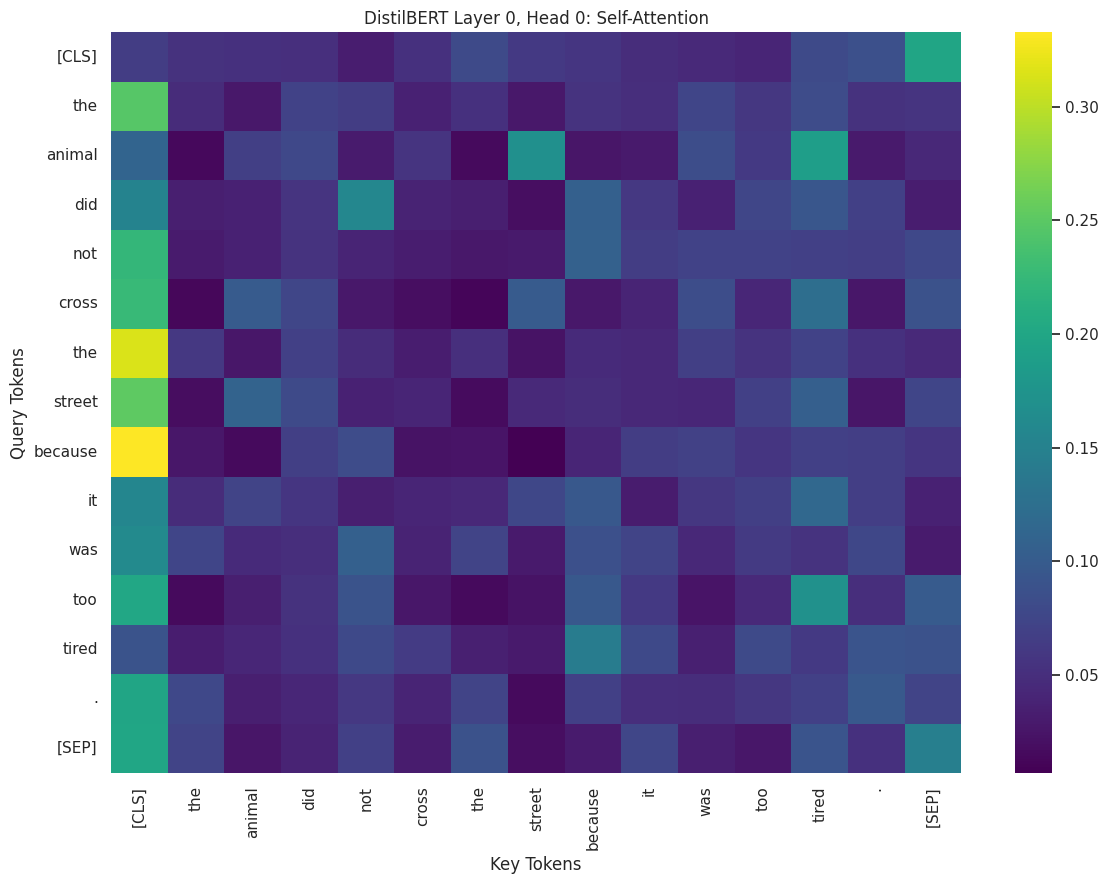

In [23]:
tokens = real_tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0].tolist()
)

plt.figure(figsize=(12, 9))

sns.heatmap(model_head_0,xticklabels=tokens,yticklabels=tokens,cmap="viridis")

plt.title("DistilBERT Layer 0, Head 0: Self-Attention")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Task 3: Multi-Head Attention, Positional Encoding, and Layer Normalization

## Task 3.1 — Understand Multi-Head Attention

## Explanation
In Task 2, you implemented scaled dot-product attention and Luong attention. Now, we will explore how a Transformer uses multiple attention heads simultaneously.

A single attention head learns attention patterns using queries (\(Q\)), keys (\(K\)), and values (\(V\)). Multi-head attention runs several attention heads in parallel and combines their outputs.

For DistilBERT, the configuration is typically:
- Hidden size: 768
- Number of attention heads: 12
- Dimension per head: \(768/12=64\)
Each head has its own query, key, and value projections. The head outputs are concatenated and passed through an output projection.
\[
\operatorname{MultiHead}(Q,K,V)
=\operatorname{Concat}(head_1,\ldots,head_{12})W^O
\]

The heads can learn different attention patterns. However, we should inspect their actual attention maps before interpreting what each head does.

## 3.2 — Extract and Visualize Real Attention Heads

In [24]:
from transformers import AutoTokenizer, AutoModel
model_name = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(
    model_name,
    attn_implementation="eager"
)

model.eval()
sentence = (
    "The animal did not cross the street "
    "because it was too tired."
)
inputs = tokenizer(
    sentence,
    return_tensors="pt"
)

print("Input sentence:")
print(sentence)
print("\nInput tokens:")
print(tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]))
print("\nInput shape:")
print(inputs["input_ids"].shape)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Input sentence:
The animal did not cross the street because it was too tired.

Input tokens:
['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']

Input shape:
torch.Size([1, 15])


## Extract attention weights

In [25]:
with torch.no_grad():
    outputs = model(**inputs,output_attentions=True)

attentions = outputs.attentions

print("Number of Transformer layers:", len(attentions))
print("Attention tensor shape:", attentions[0].shape)

Number of Transformer layers: 6
Attention tensor shape: torch.Size([1, 12, 15, 15])


## 3.3 — Calculate Attention Entropy for Each Head

In [26]:
def calculate_attention_entropy(attention_tensor):
    """
    attention_tensor shape:
    (batch_size, num_heads, query_length, key_length)
    """
    attention = attention_tensor.detach().cpu().numpy()
    attention = np.clip(attention, 1e-12, 1.0)

    entropy = -np.sum(
        attention * np.log(attention),
        axis=-1
    )

    return entropy.mean(axis=(0, 2))

first_layer_entropy = calculate_attention_entropy(
    attentions[0]
)

last_layer_entropy = calculate_attention_entropy(
    attentions[-1]
)

print("First layer entropy by head:")
print(np.round(first_layer_entropy, 4))
print("\nLast layer entropy by head:")
print(np.round(last_layer_entropy, 4))

First layer entropy by head:
[2.4939 2.0654 0.5533 1.2512 2.3135 2.1365 2.2454 1.6157 1.7954 1.2444
 0.6994 1.8173]

Last layer entropy by head:
[2.0346 1.8619 2.2673 1.8916 1.9279 1.9788 1.993  1.7625 1.9481 2.2913
 2.0655 2.0924]


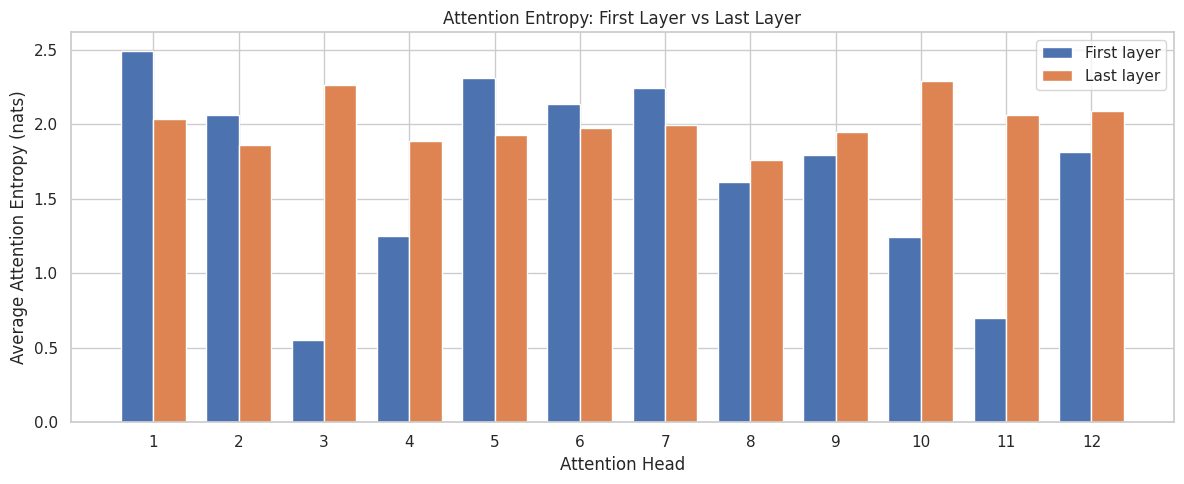

In [27]:
head_numbers = np.arange(1, len(first_layer_entropy) + 1)
plt.figure(figsize=(12, 5))
bar_width = 0.38

plt.bar(head_numbers - bar_width / 2,first_layer_entropy,width=bar_width,label="First layer")
plt.bar(head_numbers + bar_width / 2,last_layer_entropy,width=bar_width,label="Last layer")

plt.xlabel("Attention Head")
plt.ylabel("Average Attention Entropy (nats)")
plt.title("Attention Entropy: First Layer vs Last Layer")
plt.xticks(head_numbers)
plt.legend()
plt.tight_layout()
plt.show()

## Calculate and interpret the layer averages

In [28]:
print("First layer mean entropy:",round(float(first_layer_entropy.mean()), 4))
print("Last layer mean entropy:",round(float(last_layer_entropy.mean()), 4))


First layer mean entropy: 1.686
Last layer mean entropy: 2.0096


## Task 3.4 — Implement Sinusoidal Positional Encoding

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def sinusoidal_positional_encoding(
    max_positions,
    d_model
):

    positions = np.arange(max_positions)[:, np.newaxis]
    dimensions = np.arange(d_model)[np.newaxis, :]
    angle_rates = 1 / np.power(
        10000,
        (2 * (dimensions // 2)) / d_model
    )
    angle_radians = positions * angle_rates

    positional_encoding = np.zeros(
        (max_positions, d_model)
    )
    positional_encoding[:, 0::2] = np.sin(
        angle_radians[:, 0::2]
    )
    positional_encoding[:, 1::2] = np.cos(
        angle_radians[:, 1::2]
    )

    return positional_encoding

max_positions = 50
d_model = 128

pos_encoding = sinusoidal_positional_encoding(max_positions=max_positions,d_model=d_model)

print("Positional encoding shape:", pos_encoding.shape)
print("\nFirst position, first 10 dimensions:")
print(np.round(pos_encoding[0, :10], 4))

Positional encoding shape: (50, 128)

First position, first 10 dimensions:
[0. 1. 0. 1. 0. 1. 0. 1. 0. 1.]


## Visualize the positional encoding matrix

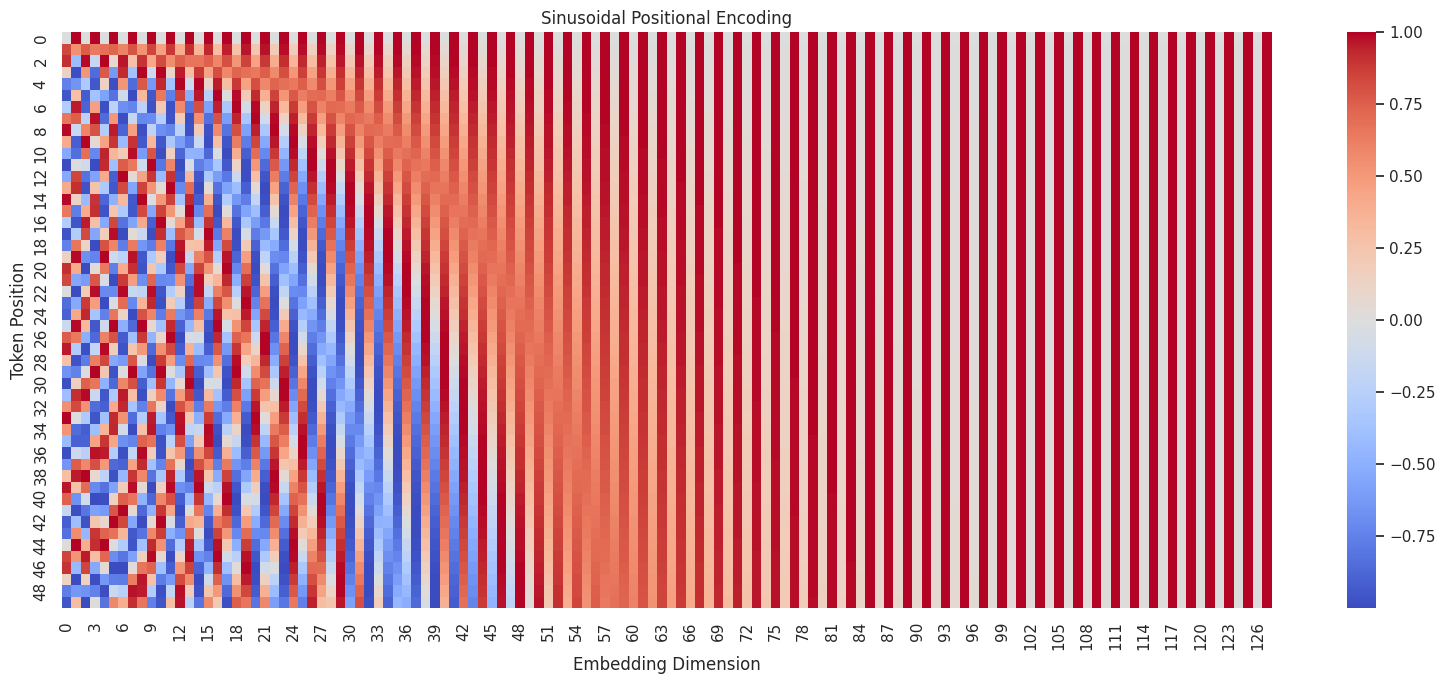

In [30]:
plt.figure(figsize=(16, 7))

sns.heatmap(pos_encoding,cmap="coolwarm",center=0)

plt.title("Sinusoidal Positional Encoding")
plt.xlabel("Embedding Dimension")
plt.ylabel("Token Position")
plt.tight_layout()
plt.show()

##3.5 — Demonstrate How Position Changes a Word Representation
We will create a random word embedding and add the positional encodings for positions 3 and 20. We will then compare cosine similarity with and without positional encoding.

Cosine similarity is:
\[
\operatorname{cos}(a,b)=
\frac{a\cdot b}{\|a\|\|b\|}
\]

## Compare representations at two positions

In [31]:
np.random.seed(42)
d_model = 128
word_embedding = np.random.randn(d_model)

position_3 = 3
position_20 = 20
pe_3 = pos_encoding[position_3]
pe_20 = pos_encoding[position_20]
representation_3 = word_embedding + pe_3
representation_20 = word_embedding + pe_20

def cosine_similarity(a, b):
    denominator = np.linalg.norm(a) * np.linalg.norm(b)

    if denominator == 0:
        return 0.0

    return float(np.dot(a, b) / denominator)

similarity_without_position = cosine_similarity(word_embedding,word_embedding)
similarity_with_position = cosine_similarity(representation_3,representation_20)
print("Similarity without positional encoding:",round(similarity_without_position, 6))
print("Similarity with positional encoding:",round(similarity_with_position, 6))

Similarity without positional encoding: 1.0
Similarity with positional encoding: 0.859478


## Task 3.6 — Inspect DistilBERT’s Learned Positional Embeddings

In [32]:
position_embeddings = (
    model.embeddings.position_embeddings.weight
)

position_array = (position_embeddings.detach().cpu().numpy())

print("Positional embedding shape:", position_array.shape)
print("\nFirst position, first 10 dimensions:")
print(np.round(position_array[0, :10], 4))


Positional embedding shape: (512, 768)

First position, first 10 dimensions:
[ 0.018  -0.0238 -0.036  -0.0238  0.0096 -0.0178 -0.0025 -0.0037  0.0064
 -0.0392]


In [33]:
from sklearn.metrics.pairwise import cosine_similarity

num_positions_to_plot = 64
selected_positions = position_array[
    :num_positions_to_plot
]

position_similarity = cosine_similarity(
    selected_positions
)
print("Similarity matrix shape:", position_similarity.shape)

Similarity matrix shape: (64, 64)


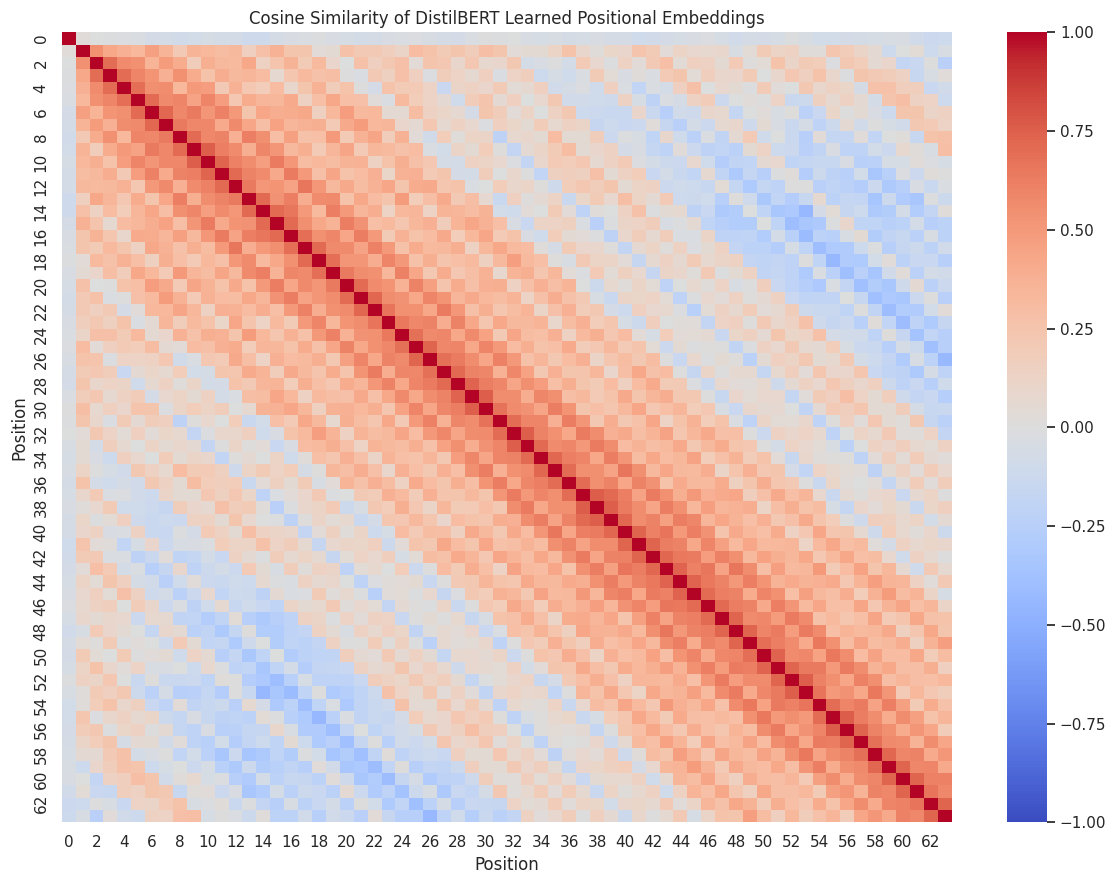

In [34]:
plt.figure(figsize=(12, 9))

sns.heatmap(position_similarity,cmap="coolwarm",center=0,vmin=-1,vmax=1)

plt.title("Cosine Similarity of DistilBERT Learned Positional Embeddings")
plt.xlabel("Position")
plt.ylabel("Position")
plt.tight_layout()
plt.show()

## Task 3.7 — Implement Layer Normalization Using NumPy

In [35]:
import numpy as np
import torch
import torch.nn as nn

np.random.seed(42)
X = np.random.randn(4, 8).astype(np.float32)

print("Input matrix:")
print(np.round(X, 3))
print("\nInput shape:", X.shape)

Input matrix:
[[ 0.497 -0.138  0.648  1.523 -0.234 -0.234  1.579  0.767]
 [-0.469  0.543 -0.463 -0.466  0.242 -1.913 -1.725 -0.562]
 [-1.013  0.314 -0.908 -1.412  1.466 -0.226  0.068 -1.425]
 [-0.544  0.111 -1.151  0.376 -0.601 -0.292 -0.602  1.852]]

Input shape: (4, 8)


In [36]:
def numpy_layer_norm(X,gamma=None,beta=None,eps=1e-5):
    mean = np.mean(X, axis=-1, keepdims=True)
    variance = np.var(X, axis=-1, keepdims=True)
    normalized = (
        (X - mean) / np.sqrt(variance + eps)
    )

    if gamma is None:
        gamma = np.ones(X.shape[-1], dtype=X.dtype)

    if beta is None:
        beta = np.zeros(X.shape[-1], dtype=X.dtype)

    return normalized * gamma + beta


numpy_result = numpy_layer_norm(X)

print("NumPy LayerNorm output:")
print(np.round(numpy_result, 4))

NumPy LayerNorm output:
[[-0.079  -1.0041  0.1409  1.4162 -1.1438 -1.1437  1.498   0.3154]
 [ 0.1664  1.439   0.174   0.1711  1.061  -1.6491 -1.4122  0.0497]
 [-0.6661  0.7579 -0.5537 -1.0948  1.9934  0.1784  0.4931 -1.1082]
 [-0.5091  0.2525 -1.2141  0.5602 -0.5745 -0.2154 -0.5757  2.2762]]


In [37]:
torch_layer_norm = nn.LayerNorm(
    normalized_shape=8,
    eps=1e-5,
    elementwise_affine=True
)
with torch.no_grad():
    torch_layer_norm.weight.fill_(1.0)
    torch_layer_norm.bias.fill_(0.0)

torch_result = torch_layer_norm(
    torch.tensor(X)
).detach().cpu().numpy()

print("PyTorch LayerNorm output:")
print(np.round(torch_result, 4))

print(
    "\nOutputs are close:",
    np.allclose(numpy_result,torch_result,atol=1e-5)
)
print(
    "Maximum absolute difference:",
    np.max(np.abs(numpy_result - torch_result))
)

PyTorch LayerNorm output:
[[-0.079  -1.0041  0.1409  1.4162 -1.1438 -1.1437  1.498   0.3154]
 [ 0.1664  1.439   0.174   0.1711  1.061  -1.6491 -1.4122  0.0497]
 [-0.6661  0.7579 -0.5537 -1.0948  1.9934  0.1784  0.4931 -1.1082]
 [-0.5091  0.2525 -1.2141  0.5602 -0.5745 -0.2154 -0.5757  2.2762]]

Outputs are close: True
Maximum absolute difference: 2.3841858e-07


In [38]:
print("Mean of each normalized token:")
print(np.round(numpy_result.mean(axis=1), 6))
print("\nVariance of each normalized token:")
print(np.round(numpy_result.var(axis=1), 6))

Mean of each normalized token:
[-0.  0.  0. -0.]

Variance of each normalized token:
[0.999979 0.999984 0.999988 0.999987]


In [39]:
def numpy_batch_norm(X, eps=1e-5):

    feature_mean = np.mean(X, axis=0, keepdims=True)
    feature_variance = np.var(X, axis=0, keepdims=True)

    normalized = ((X - feature_mean)/ np.sqrt(feature_variance + eps))
    return normalized

batch_norm_result = numpy_batch_norm(X)

print("BatchNorm demonstration output:")
print(np.round(batch_norm_result, 4))
print("\nFeature means across rows:")
print(np.round(batch_norm_result.mean(axis=0), 6))
print("\nFeature variances across rows:")
print(np.round(batch_norm_result.var(axis=0), 6))

BatchNorm demonstration output:
[[ 1.6024 -1.3754  1.6177  1.4044 -0.5802  0.5997  1.4627  0.4868]
 [-0.1585  1.3339  0.0076 -0.4357  0.0305 -1.731  -1.3003 -0.5756]
 [-1.1489  0.4253 -0.6366 -1.3116  1.5999  0.6114  0.1986 -1.2647]
 [-0.2951 -0.3838 -0.9887  0.3428 -1.0502  0.5199 -0.361   1.3536]]

Feature means across rows:
[-0.  0. -0.  0.  0.  0. -0.  0.]

Feature variances across rows:
[0.999967 0.999842 0.999979 0.999991 0.999984 0.999981 0.999993 0.999994]


In [40]:
print("LayerNorm: mean and variance for each token")
print("Means:", np.round(numpy_result.mean(axis=1), 4))
print("Variances:", np.round(numpy_result.var(axis=1), 4))
print("\nBatchNorm: mean and variance for each feature")
print("Means:", np.round(batch_norm_result.mean(axis=0), 4))
print("Variances:", np.round(batch_norm_result.var(axis=0), 4))


LayerNorm: mean and variance for each token
Means: [-0.  0.  0. -0.]
Variances: [1. 1. 1. 1.]

BatchNorm: mean and variance for each feature
Means: [-0.  0. -0.  0.  0.  0. -0.  0.]
Variances: [1.     0.9998 1.     1.     1.     1.     1.     1.    ]


In [41]:
embedding_layer_norm = model.embeddings.LayerNorm

gamma = (embedding_layer_norm.weight.detach().cpu().numpy())
beta = (embedding_layer_norm.bias.detach().cpu().numpy())

print("Gamma shape:", gamma.shape)
print("Beta shape:", beta.shape)
print("\nFirst 10 gamma values:")
print(np.round(gamma[:10], 4))
print("\nFirst 10 beta values:")
print(np.round(beta[:10], 4))
print("\nGamma mean:", round(float(gamma.mean()), 4))
print("Beta mean:", round(float(beta.mean()), 4))

Gamma shape: (768,)
Beta shape: (768,)

First 10 gamma values:
[0.8445 0.7974 0.7331 0.7594 0.8013 0.7861 0.817  0.8177 0.8369 0.7073]

First 10 beta values:
[ 0.0443  0.0614  0.0692  0.0874 -0.0584 -0.1601  0.1443 -0.0606 -0.0279
  0.1222]

Gamma mean: 0.7444
Beta mean: -0.01


# Task 4: Transformer Encoder Architecture and Masked Attention

## Print the model architecture

In [42]:
print(model)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=True)
          (lin2): L

## Task 4.2 — Inspect Important Encoder Modules
## Print module names and dimensions

In [43]:
print("Model class:", model.__class__.__name__)
print("Number of encoder layers:", len(model.transformer.layer))
print("Hidden size:", model.config.dim)
print("Attention heads:", model.config.n_heads)
print("Maximum positions:", model.config.max_position_embeddings)
print("\nEmbedding modules:")
print(model.embeddings)

print("\nFirst Transformer layer:")
print(model.transformer.layer[0])


Model class: DistilBertModel
Number of encoder layers: 6
Hidden size: 768
Attention heads: 12
Maximum positions: 512

Embedding modules:
Embeddings(
  (word_embeddings): Embedding(30522, 768, padding_idx=0)
  (position_embeddings): Embedding(512, 768)
  (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
  (dropout): Dropout(p=0.1, inplace=False)
)

First Transformer layer:
TransformerBlock(
  (attention): DistilBertSelfAttention(
    (q_lin): Linear(in_features=768, out_features=768, bias=True)
    (k_lin): Linear(in_features=768, out_features=768, bias=True)
    (v_lin): Linear(in_features=768, out_features=768, bias=True)
    (out_lin): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
  (ffn): FFN(
    (dropout): Dropout(p=0.1, inplace=False)
    (lin1): Linear(in_features=768, out_features=3072, bias=True)
    (lin2): Linear(in_features=3072, 

In [44]:
first_layer = model.transformer.layer[0]

print("Query projection:")
print(first_layer.attention.q_lin)
print("\nKey projection:")
print(first_layer.attention.k_lin)
print("\nValue projection:")
print(first_layer.attention.v_lin)
print("\nAttention output projection:")
print(first_layer.attention.out_lin)
print("\nFeed-forward input projection:")
print(first_layer.ffn.lin1)
print("\nFeed-forward output projection:")
print(first_layer.ffn.lin2)

Query projection:
Linear(in_features=768, out_features=768, bias=True)

Key projection:
Linear(in_features=768, out_features=768, bias=True)

Value projection:
Linear(in_features=768, out_features=768, bias=True)

Attention output projection:
Linear(in_features=768, out_features=768, bias=True)

Feed-forward input projection:
Linear(in_features=768, out_features=3072, bias=True)

Feed-forward output projection:
Linear(in_features=3072, out_features=768, bias=True)


##4.3 — Count Parameters by Model Component

In [45]:
from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt

parameter_groups = defaultdict(int)

for name, parameter in model.named_parameters():
    name_lower = name.lower()

    if "embeddings" in name_lower:
        group = "Embeddings"
    elif "attention" in name_lower:
        group = "Attention"
    elif "ffn" in name_lower:
        group = "Feed-forward"
    elif "layer_norm" in name_lower or "norm" in name_lower:
        group = "Layer Normalization"
    else:
        group = "Other"

    parameter_groups[group] += parameter.numel()

total_parameters = sum(parameter_groups.values())

parameter_summary = pd.DataFrame([
    {
        "Component": group,
        "Parameters": count,
        "Percentage": count / total_parameters * 100
    }
    for group, count in parameter_groups.items()
]).sort_values("Parameters", ascending=False)

print(parameter_summary.to_string(index=False))
print("\nTotal backbone parameters:", f"{total_parameters:,}")

          Component  Parameters  Percentage
       Feed-forward    28334592   42.696447
         Embeddings    23835648   35.917139
          Attention    14174208   21.358639
Layer Normalization       18432    0.027775

Total backbone parameters: 66,362,880


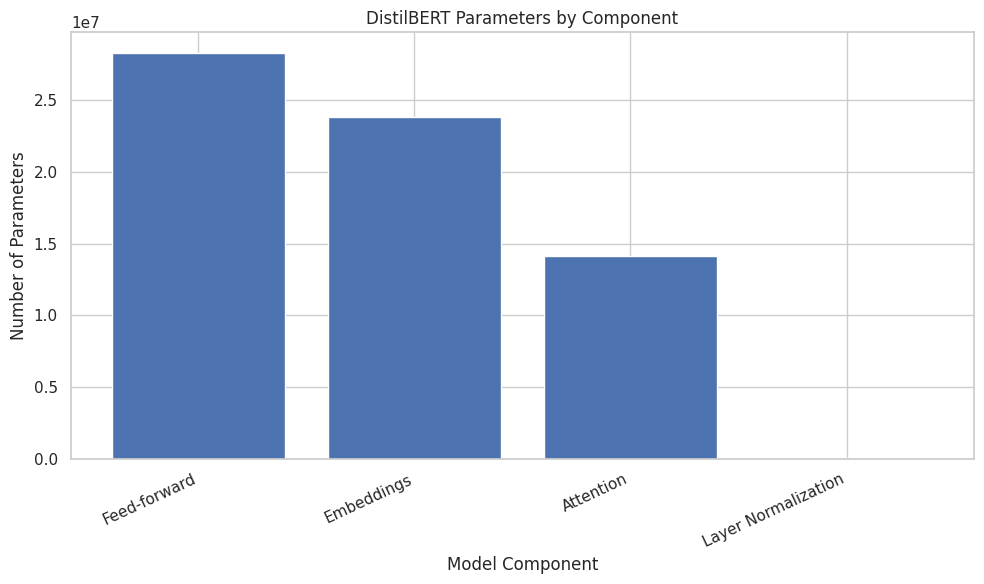

In [46]:
plt.figure(figsize=(10, 6))

plt.bar(
    parameter_summary["Component"],
    parameter_summary["Parameters"]
)

plt.title("DistilBERT Parameters by Component")
plt.xlabel("Model Component")
plt.ylabel("Number of Parameters")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

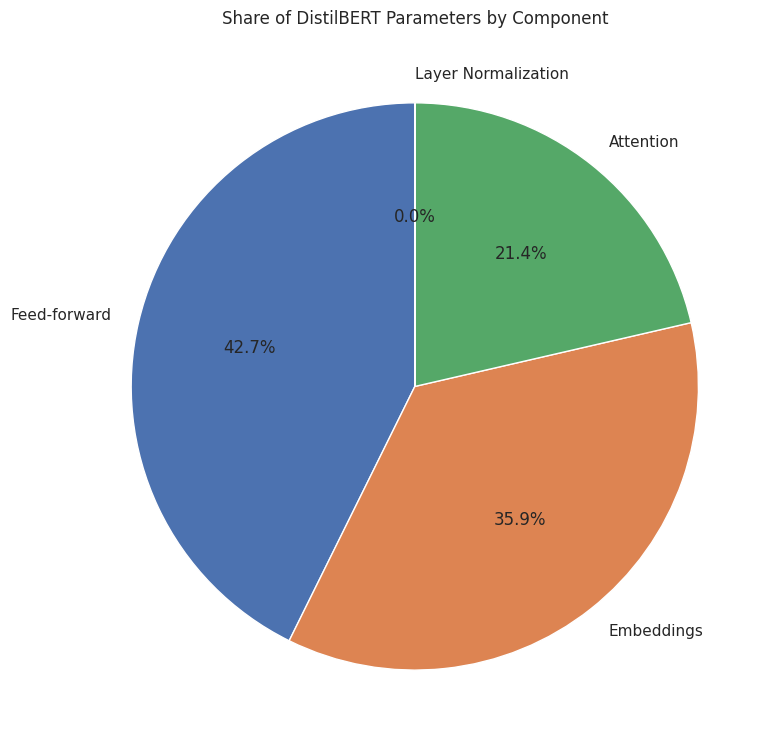

In [47]:
plt.figure(figsize=(8, 8))

plt.pie(parameter_summary["Parameters"],labels=parameter_summary["Component"],autopct="%1.1f%%",startangle=90)
plt.title("Share of DistilBERT Parameters by Component")
plt.tight_layout()
plt.show()

## Task 4.4 — Predict Masked Words with DistilBERT

In [48]:
from transformers import pipeline

fill_masker = pipeline(
    "fill-mask",
    model="distilbert-base-uncased",
    tokenizer="distilbert-base-uncased"
)

print("Masked language model loaded successfully.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Masked language model loaded successfully.


In [49]:
masked_sentences = [
    "The animal did not cross the [MASK] because it was tired.",
    "Machine learning is a branch of [MASK].",
    "She opened the book and started to [MASK]."
]

for sentence in masked_sentences:
    print("\nSentence:", sentence)

    predictions = fill_masker(sentence,top_k=3)

    for rank, prediction in enumerate(predictions, start=1):
        print(f"{rank}. {prediction['token_str'].strip()} "f"| score={prediction['score']:.4f}")


Sentence: The animal did not cross the [MASK] because it was tired.
1. threshold | score=0.0675
2. ground | score=0.0407
3. road | score=0.0406

Sentence: Machine learning is a branch of [MASK].
1. robotics | score=0.3732
2. mathematics | score=0.3196
3. neuroscience | score=0.0499

Sentence: She opened the book and started to [MASK].
1. read | score=0.5492
2. write | score=0.2515
3. chew | score=0.0085


## Task 4.5 — Visualize Bidirectional Encoder Attention
## Extract the last-layer attention matrix

In [50]:
sentence = (
    "The animal did not cross the street "
    "because it was too tired."
)

inputs = tokenizer(sentence,return_tensors="pt")
model.eval()

with torch.no_grad():
    outputs = model(**inputs,output_attentions=True)

last_layer_attention = outputs.attentions[-1]

print("Last-layer attention shape:")
print(last_layer_attention.shape)

mean_attention = (last_layer_attention[0].mean(dim=0).cpu().numpy())

tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("\nTokens:")
print(tokens)
print("\nMean attention matrix shape:")
print(mean_attention.shape)

Last-layer attention shape:
torch.Size([1, 12, 15, 15])

Tokens:
['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']

Mean attention matrix shape:
(15, 15)


## Plot the averaged attention matrix

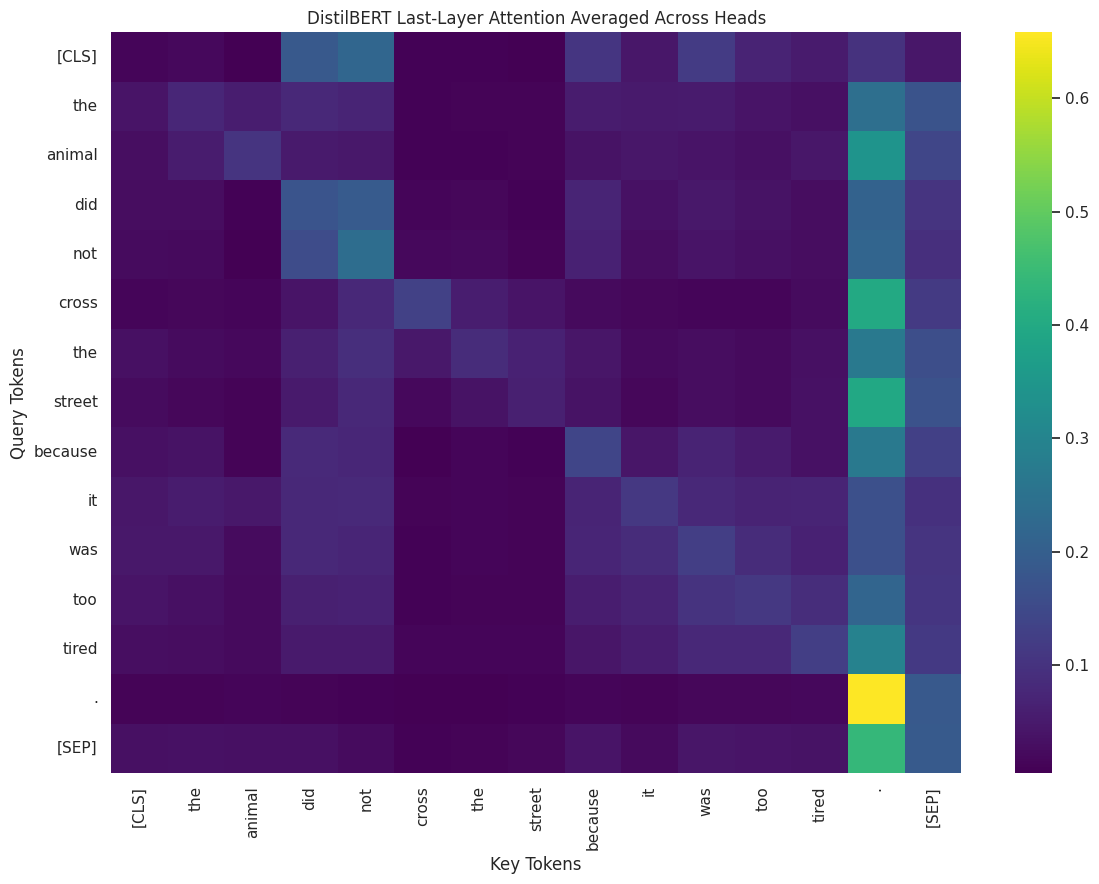

In [51]:
plt.figure(figsize=(12, 9))

sns.heatmap(mean_attention,xticklabels=tokens,yticklabels=tokens,cmap="viridis")

plt.title("DistilBERT Last-Layer Attention Averaged Across Heads")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Check attention above and below the diagonal

In [52]:
sequence_length = mean_attention.shape[0]

upper_triangle = mean_attention[
    np.triu_indices(sequence_length, k=1)
]

lower_triangle = mean_attention[
    np.tril_indices(sequence_length, k=-1)
]

print("Maximum attention above diagonal:",float(upper_triangle.max()))
print("Maximum attention below diagonal:",float(lower_triangle.max()))
print("Has positive attention above diagonal:",bool(np.any(upper_triangle > 0)))
print("Has positive attention below diagonal:",bool(np.any(lower_triangle > 0)))

Maximum attention above diagonal: 0.39907896518707275
Maximum attention below diagonal: 0.4407414495944977
Has positive attention above diagonal: True
Has positive attention below diagonal: True


## Task 4.6 — Implement a Causal Mask with NumPy

In [53]:
sequence_length = 6

causal_mask = np.triu(
    np.full((sequence_length, sequence_length),-np.inf),
    k=1)
causal_mask = np.tril(
    np.zeros((sequence_length, sequence_length))) + np.triu(
    np.full((sequence_length, sequence_length),-np.inf),
    k=1)

print("Causal mask:")
print(causal_mask)

Causal mask:
[[  0. -inf -inf -inf -inf -inf]
 [  0.   0. -inf -inf -inf -inf]
 [  0.   0.   0. -inf -inf -inf]
 [  0.   0.   0.   0. -inf -inf]
 [  0.   0.   0.   0.   0. -inf]
 [  0.   0.   0.   0.   0.   0.]]


## Visualize the causal mask

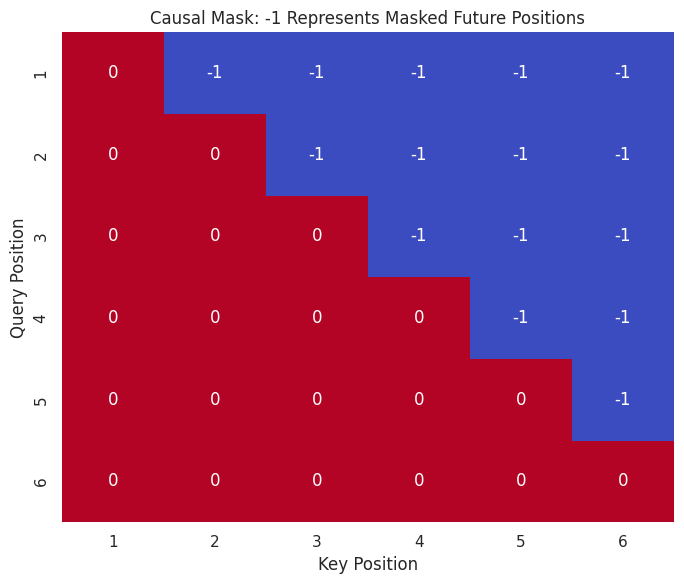

In [54]:
mask_for_plot = np.where(np.isneginf(causal_mask),-1,0)
plt.figure(figsize=(7, 6))

sns.heatmap(mask_for_plot,annot=True,fmt="d",cmap="coolwarm",xticklabels=range(1, sequence_length + 1),yticklabels=range(1, sequence_length + 1),cbar=False)

plt.title("Causal Mask: -1 Represents Masked Future Positions")
plt.xlabel("Key Position")
plt.ylabel("Query Position")
plt.tight_layout()
plt.show()

## Apply the mask before softmax

In [55]:
def stable_softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

np.random.seed(42)
attention_scores = np.random.randn(sequence_length,sequence_length)
masked_scores = attention_scores + causal_mask

causal_attention_weights = stable_softmax(
    masked_scores,
    axis=-1)

print("Masked attention scores:")
print(masked_scores)
print("\nCausal attention weights:")
print(np.round(causal_attention_weights, 4))
print("\nSum of each row:")
print(causal_attention_weights.sum(axis=-1))

Masked attention scores:
[[ 0.49671415        -inf        -inf        -inf        -inf        -inf]
 [ 1.57921282  0.76743473        -inf        -inf        -inf        -inf]
 [ 0.24196227 -1.91328024 -1.72491783        -inf        -inf        -inf]
 [-0.90802408 -1.4123037   1.46564877 -0.2257763         -inf        -inf]
 [-0.54438272  0.11092259 -1.15099358  0.37569802 -0.60063869        -inf]
 [-0.60170661  1.85227818 -0.01349722 -1.05771093  0.82254491 -1.22084365]]

Causal attention weights:
[[1.     0.     0.     0.     0.     0.    ]
 [0.6925 0.3075 0.     0.     0.     0.    ]
 [0.7963 0.0923 0.1114 0.     0.     0.    ]
 [0.0698 0.0422 0.7498 0.1382 0.     0.    ]
 [0.1444 0.2781 0.0787 0.3623 0.1365 0.    ]
 [0.0506 0.5887 0.0911 0.0321 0.2102 0.0272]]

Sum of each row:
[1. 1. 1. 1. 1. 1.]


## Verify future-token attention is zero

In [56]:
future_attention = causal_attention_weights[
    np.triu_indices(sequence_length, k=1)]

print("Maximum attention assigned to future tokens:",float(future_attention.max()))
print("All future-token attention weights are zero:",bool(np.allclose(future_attention, 0.0)))
print(
    "All row sums equal 1:",
    bool(
        np.allclose(causal_attention_weights.sum(axis=-1),1.0)
    )
)

Maximum attention assigned to future tokens: 0.0
All future-token attention weights are zero: True
All row sums equal 1: True


## 4.7 — Inspect Causal Attention

In [57]:
from transformers import AutoTokenizer, AutoModelForCausalLM

gpt2_name = "gpt2"
gpt2_tokenizer = AutoTokenizer.from_pretrained(gpt2_name)
gpt2_model = AutoModelForCausalLM.from_pretrained(gpt2_name,attn_implementation="eager")
gpt2_model.eval()

print("Model:", gpt2_name)
print("Number of layers:", gpt2_model.config.n_layer)
print("Number of attention heads:", gpt2_model.config.n_head)
print("Hidden size:", gpt2_model.config.n_embd)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Model: gpt2
Number of layers: 12
Number of attention heads: 12
Hidden size: 768


## Extract the last-layer attention weights

In [58]:
gpt_sentence = "Artificial intelligence can help people"
gpt_inputs = gpt2_tokenizer(gpt_sentence,return_tensors="pt")

with torch.no_grad():
    gpt_outputs = gpt2_model(**gpt_inputs,output_attentions=True)

gpt_attentions = gpt_outputs.attentions

print("Number of layers:", len(gpt_attentions))
print("Last-layer attention shape:", gpt_attentions[-1].shape)

gpt_tokens = gpt2_tokenizer.convert_ids_to_tokens(
    gpt_inputs["input_ids"][0])
print("Tokens:", gpt_tokens)

Number of layers: 12
Last-layer attention shape: torch.Size([1, 12, 6, 6])
Tokens: ['Art', 'ificial', 'Ġintelligence', 'Ġcan', 'Ġhelp', 'Ġpeople']


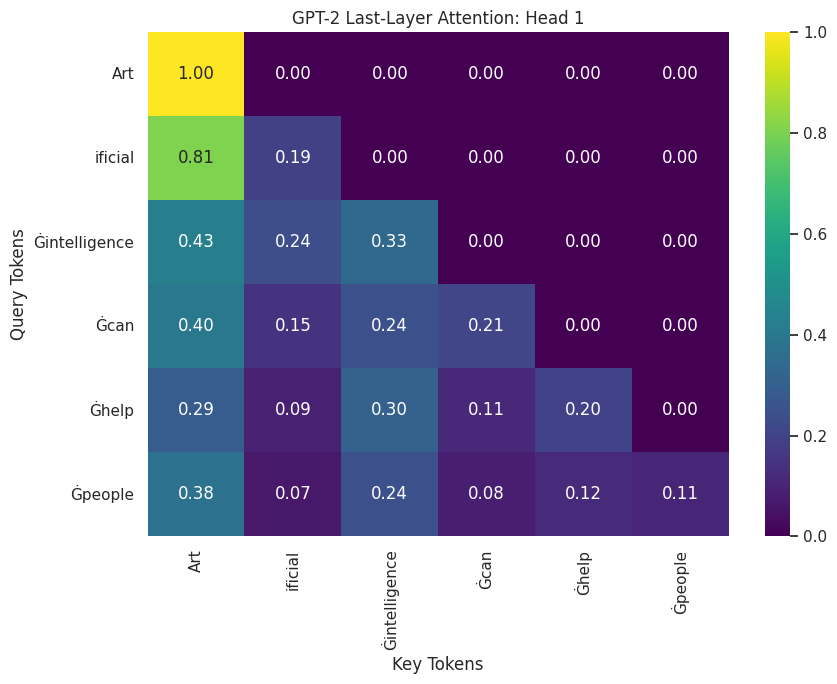

In [59]:
gpt_attention_head = (gpt_attentions[-1][0, 0].detach().cpu().numpy())
plt.figure(figsize=(9, 7))

sns.heatmap(gpt_attention_head,annot=True,fmt=".2f",xticklabels=gpt_tokens,yticklabels=gpt_tokens,cmap="viridis")

plt.title("GPT-2 Last-Layer Attention: Head 1")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Verify future positions are masked

In [60]:
future_values = gpt_attention_head[
    np.triu_indices(gpt_attention_head.shape[0],k=1)]

print("Maximum future-position attention:",float(future_values.max()) if future_values.size else 0.0)
print("Future attention is approximately zero:",bool(np.allclose(future_values, 0.0, atol=1e-6)))

Maximum future-position attention: 0.0
Future attention is approximately zero: True


##4.8 Padding mask vs causal mask

In [61]:
distil_sentences = ["Transformers learn patterns from language.","Transformers learn patterns."]

batch_inputs = tokenizer(distil_sentences,padding=True,truncation=True,return_tensors="pt")

print("Input IDs:")
print(batch_inputs["input_ids"])
print("\nAttention mask:")
print(batch_inputs["attention_mask"])
print("\nTokens for each sentence:")

for row in batch_inputs["input_ids"]:
    print(tokenizer.convert_ids_to_tokens(row))

Input IDs:
tensor([[  101, 19081,  4553,  7060,  2013,  2653,  1012,   102],
        [  101, 19081,  4553,  7060,  1012,   102,     0,     0]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 0, 0]])

Tokens for each sentence:
['[CLS]', 'transformers', 'learn', 'patterns', 'from', 'language', '.', '[SEP]']
['[CLS]', 'transformers', 'learn', 'patterns', '.', '[SEP]', '[PAD]', '[PAD]']


In [62]:
with torch.no_grad():
    batch_outputs = model(**batch_inputs,output_attentions=True)

batch_last_attention = batch_outputs.attentions[-1]
print("Last-layer attention shape:",batch_last_attention.shape)

Last-layer attention shape: torch.Size([2, 12, 8, 8])


In [63]:
second_attention_mask = batch_inputs["attention_mask"][1]

padding_positions = (
    second_attention_mask == 0
).nonzero(as_tuple=True)[0]

print("Padding token positions:", padding_positions.tolist())

if len(padding_positions) > 0:
    second_sentence_attention = batch_last_attention[1]

    padding_attention = second_sentence_attention[
        :, :, padding_positions
    ]
    print("Maximum attention weight assigned to padding keys:",float(padding_attention.max()))
    print("Mean attention weight assigned to padding keys:",float(padding_attention.mean()))
else:
    print("No padding was added. Try sentences with a larger length difference.")

Padding token positions: [6, 7]
Maximum attention weight assigned to padding keys: 0.0
Mean attention weight assigned to padding keys: 0.0


## Compare padding and causal masks


### Padding Mask vs Causal Mask

| Feature | Padding Mask | Causal Mask |
|---|---|---|
| Main purpose | Ignore padding tokens | Block future tokens |
| Common use | Encoder and decoder inputs with padding | Autoregressive decoder attention |
| Restricted positions | Positions representing padding | Positions later than the current query |
| DistilBERT encoder | Used when inputs contain padding | Not normally used for standard encoder self-attention |
| GPT-2 | May also use a padding mask when padding is present | Used to prevent access to future tokens |

A padding mask and a causal mask are not interchangeable. In some architectures, both restrictions can be applied simultaneously.


# Task 5: Transformer Decoder, Cross-Attention, and Inference



## 5.1 Transformer Decoder Architecture

In the original encoder-decoder Transformer, each decoder block contains:

1. Masked multi-head self-attention.
2. A residual connection and Layer Normalization.
3. Cross-attention over the encoder output.
4. Another residual connection and Layer Normalization.
5. A feed-forward neural network.
6. A final residual connection and Layer Normalization.

The decoder's masked self-attention prevents each output position from attending to future output tokens. Cross-attention allows the decoder to use information from the encoder output.

After the decoder produces hidden representations, a linear projection and softmax produce a probability distribution over possible next tokens.

### Model families

- **DistilBERT:** encoder-only; commonly used for classification and contextual representations.
- **GPT-2:** decoder-only; commonly used for autoregressive text generation.
- **T5:** encoder-decoder; supports text-to-text tasks such as translation and summarization.

These model families have different architectures, so not every model contains every component of the original Transformer.


## Task 5.2 — Understand Cross-Attention
In cross-attention, the query vectors come from the decoder, while the key and value vectors come from the encoder output.
\[
Q = H_{\text{decoder}}W^Q
\]

\[
K = H_{\text{encoder}}W^K,\quad
V = H_{\text{encoder}}W^V
\]

\[
\operatorname{Attention}(Q,K,V)=
\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
\]

This enables each decoder position to retrieve relevant information from the input sequence.


### Self-Attention vs Cross-Attention

**Self-attention:** Queries, keys, and values are derived from the same sequence representation.

**Cross-attention:** Queries come from one sequence, typically the decoder, while keys and values come from another sequence, typically the encoder output.

Luong attention, implemented in Task 2, is a form of attention that scores decoder states against encoder states. Transformer cross-attention uses learned projections and scaled dot-product attention, usually across multiple heads.


## 5.3 — Run an encoder-decoder model

## Load the pretrained T5 model

In [64]:
import time

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    pipeline
)

t5_name = "t5-small"
t5_tokenizer = AutoTokenizer.from_pretrained(t5_name)
t5_model = AutoModelForSeq2SeqLM.from_pretrained(t5_name,attn_implementation="eager")

t5_model.eval()
print("Model:", t5_name)
print("Model class:", t5_model.__class__.__name__)
print("Encoder layers:", t5_model.config.num_layers)
print("Decoder layers:", t5_model.config.num_decoder_layers)
print("Attention heads:", t5_model.config.num_heads)

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Model: t5-small
Model class: T5ForConditionalGeneration
Encoder layers: 6
Decoder layers: 6
Attention heads: 8


## Translate three English sentences into French

In [65]:
import torch
t5_model.eval()
english_sentences = [
    "The house is small.",
    "Machine learning helps us discover patterns in data.",
    "Artificial intelligence is changing the way people work."
]

translation_results = []
for sentence in english_sentences:
    input_text = "translate English to French: " + sentence
    inputs = t5_tokenizer(
        input_text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    inputs = {
        key: value.to(next(t5_model.parameters()).device)
        for key, value in inputs.items()
    }
    with torch.no_grad():
        output_ids = t5_model.generate(**inputs,max_new_tokens=60,num_beams=4,early_stopping=True)

    translated_text = t5_tokenizer.decode(output_ids[0],skip_special_tokens=True)

    translation_results.append({
        "English Sentence": sentence,
        "French Translation": translated_text
    })

translation_df = pd.DataFrame(translation_results)
display(translation_df)

,English Sentence,French Translation
0,The house is small.,La maison est petite.
1,Machine learning helps us discover patterns in...,L'apprentissage en machine nous aide à découvr...
2,Artificial intelligence is changing the way pe...,L'intelligence artificielle change la façon do...


## Summarize a passage

In [66]:
passage = """
Artificial intelligence and machine learning are increasingly used
in healthcare, education, finance, transportation, and manufacturing.
These technologies help organizations analyze large amounts of data,
automate repetitive tasks, and make better decisions. Deep learning
models can recognize images, understand language, and generate content.
However, AI systems may also introduce challenges related to bias,
privacy, transparency, reliability, and human oversight.
"""

summary_prompt = "summarize: " + passage.strip()

inputs = t5_tokenizer(
    summary_prompt,
    return_tensors="pt",
    truncation=True,
    max_length=512
)

device = next(t5_model.parameters()).device
inputs = {key: value.to(device) for key, value in inputs.items()}
t5_model.eval()

with torch.no_grad():
    summary_ids = t5_model.generate(
        **inputs,
        max_new_tokens=60,
        num_beams=4,
        early_stopping=True
    )

summary_result = t5_tokenizer.decode(
    summary_ids[0],
    skip_special_tokens=True
)

print("Original passage:\n")
print(passage)
print("\nGenerated summary:\n")
print(summary_result)

Original passage:


Artificial intelligence and machine learning are increasingly used
in healthcare, education, finance, transportation, and manufacturing.
These technologies help organizations analyze large amounts of data,
automate repetitive tasks, and make better decisions. Deep learning
models can recognize images, understand language, and generate content.
However, AI systems may also introduce challenges related to bias,
privacy, transparency, reliability, and human oversight.


Generated summary:

artificial intelligence and machine learning are increasingly used in healthcare, education, finance, transportation, and manufacturing. AI systems may also introduce challenges related to bias, privacy, transparency, reliability, and human oversight.


## Task 5.4 — Extract and Visualize T5 Cross-Attention

In [67]:
source_sentence = "The house is small."
target_sentence = "La maison est petite."
source_prompt = "translate English to French: " + source_sentence

encoder_inputs = t5_tokenizer(source_prompt,return_tensors="pt")
target_inputs = t5_tokenizer(target_sentence,return_tensors="pt")
source_tokens = t5_tokenizer.convert_ids_to_tokens(
    encoder_inputs["input_ids"][0]
)
target_tokens = t5_tokenizer.convert_ids_to_tokens(
    target_inputs["input_ids"][0]
)

print("Source tokens:")
print(source_tokens)
print("\nTarget tokens:")
print(target_tokens)

Source tokens:
['▁translate', '▁English', '▁to', '▁French', ':', '▁The', '▁house', '▁is', '▁small', '.', '</s>']

Target tokens:
['▁La', '▁maison', '▁est', '▁petite', '.', '</s>']


## Run T5 with labels and request attention weights

In [68]:
with torch.no_grad():
    t5_outputs = t5_model(
        input_ids=encoder_inputs["input_ids"],
        attention_mask=encoder_inputs["attention_mask"],
        labels=target_inputs["input_ids"],
        output_attentions=True,
        return_dict=True
    )

print("Loss:", float(t5_outputs.loss))
print("Number of cross-attention layers:", len(t5_outputs.cross_attentions))

last_cross_attention = t5_outputs.cross_attentions[-1]

print(
    "Last decoder layer cross-attention shape:",
    last_cross_attention.shape)

Loss: 0.15406204760074615
Number of cross-attention layers: 6
Last decoder layer cross-attention shape: torch.Size([1, 8, 6, 11])


## Average cross-attention across heads

In [69]:
cross_attention_matrix = (last_cross_attention[0].mean(dim=0).detach().cpu().numpy())

print("Mean cross-attention matrix shape:")
print(cross_attention_matrix.shape)
print("\nTarget token count:", len(target_tokens))
print("Source token count:", len(source_tokens))


Mean cross-attention matrix shape:
(6, 11)

Target token count: 6
Source token count: 11


## Plot the cross-attention matrix

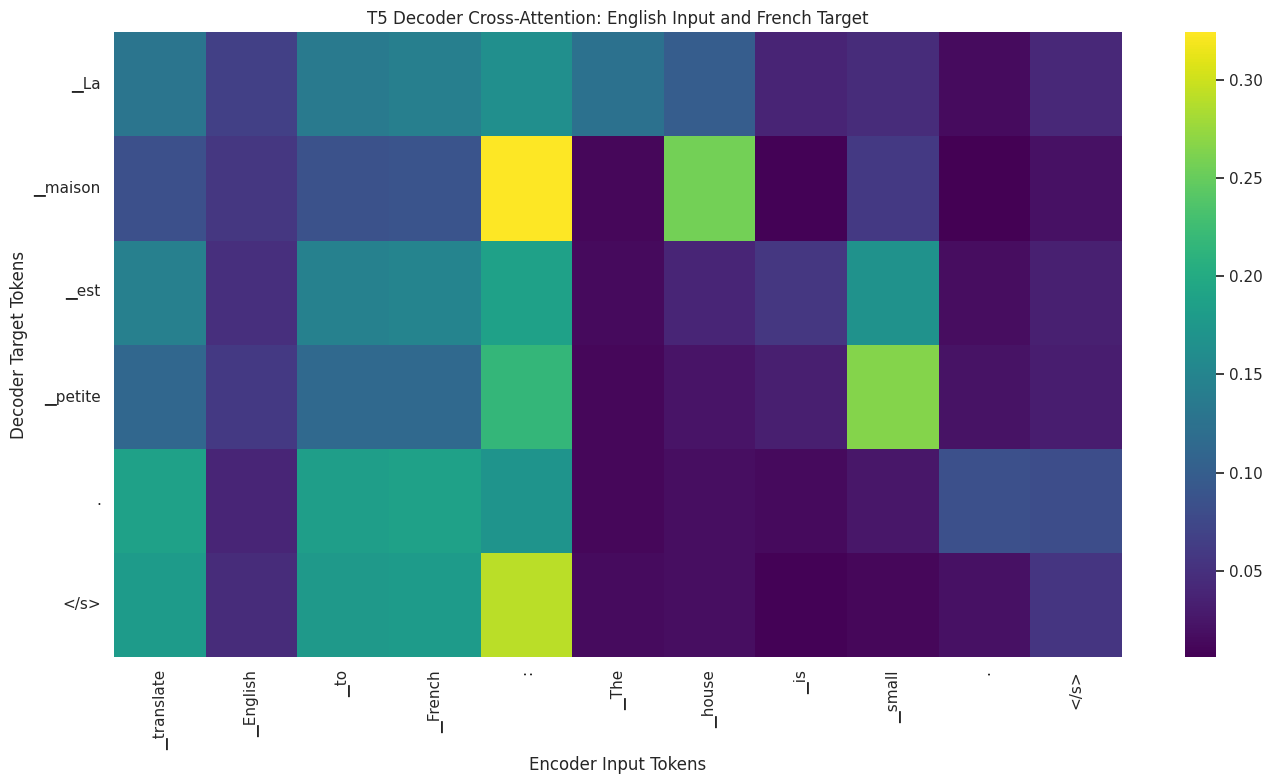

In [70]:
plt.figure(figsize=(14, 8))
sns.heatmap(cross_attention_matrix,xticklabels=source_tokens,yticklabels=target_tokens,cmap="viridis")

plt.title("T5 Decoder Cross-Attention: English Input and French Target")
plt.xlabel("Encoder Input Tokens")
plt.ylabel("Decoder Target Tokens")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 5.5 — Inference is autoregressive — manual loop

In [71]:
from transformers import AutoTokenizer, AutoModelForCausalLM

gpt2_name = "gpt2"
gpt2_tokenizer = AutoTokenizer.from_pretrained(gpt2_name)

gpt2_model = AutoModelForCausalLM.from_pretrained(
    gpt2_name,
    attn_implementation="eager"
)

gpt2_model.eval()
gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token
print("GPT-2 loaded successfully.")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 loaded successfully.


## Generate 20 tokens manually

In [72]:
def manual_greedy_generation(model, tokenizer, prompt, max_new_tokens=20):
    model.eval()

    input_ids = tokenizer(
        prompt,
        return_tensors="pt"
    )["input_ids"]

    generated_ids = input_ids.clone()
    past_key_values = None

    with torch.no_grad():
        for _ in range(max_new_tokens):
            if past_key_values is None:
                model_inputs = {
                    "input_ids": generated_ids,
                    "use_cache": True
                }
            else:
                model_inputs = {
                    "input_ids": generated_ids[:, -1:],
                    "past_key_values": past_key_values,
                    "use_cache": True
                }

            outputs = model(**model_inputs)

            next_token_logits = outputs.logits[:, -1, :]
            next_token = torch.argmax(
                next_token_logits,
                dim=-1,
                keepdim=True
            )

            generated_ids = torch.cat(
                [generated_ids, next_token],
                dim=-1
            )

            past_key_values = outputs.past_key_values

    return tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    )


prompt = "Artificial intelligence will"

manual_output = manual_greedy_generation(
    gpt2_model,
    gpt2_tokenizer,
    prompt,
    max_new_tokens=20
)

print("Prompt:", prompt)
print("\nManual greedy output:\n")
print(manual_output)


Prompt: Artificial intelligence will

Manual greedy output:

Artificial intelligence will be able to do things like search for and find people, and to do things like find out who


## Compare against generate()

In [73]:
prompt = "Artificial intelligence will"

prompt_ids = gpt2_tokenizer(
    prompt,
    return_tensors="pt"
)["input_ids"]

with torch.no_grad():
    generated_ids = gpt2_model.generate(
        input_ids=prompt_ids,
        max_new_tokens=20,
        do_sample=False,
        num_beams=1,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

generate_output = gpt2_tokenizer.decode(
    generated_ids[0],
    skip_special_tokens=True
)

print("Manual generation:\n")
print(manual_output)
print("\nUsing model.generate():\n")
print(generate_output)
print("\nOutputs match:",manual_output == generate_output)

Manual generation:

Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

Using model.generate():

Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

Outputs match: True


## 5.6 — Decoding strategies

In [74]:
generation_prompt = "The future of artificial intelligence"

generation_input_ids = gpt2_tokenizer(
    generation_prompt,
    return_tensors="pt"
)["input_ids"]

def decode_generation(output_ids):
    return gpt2_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )
generation_results = {}
with torch.no_grad():
    output = gpt2_model.generate(
        generation_input_ids,
        max_new_tokens=40,
        do_sample=False,
        num_beams=1,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

generation_results["Greedy"] = decode_generation(output)
with torch.no_grad():
    output = gpt2_model.generate(
        generation_input_ids,
        max_new_tokens=40,
        do_sample=False,
        num_beams=5,
        early_stopping=True,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

generation_results["Beam search (5 beams)"] = decode_generation(output)
for temperature, seed in [(0.7, 42), (1.5, 123)]:
    torch.manual_seed(seed)

    with torch.no_grad():
        output = gpt2_model.generate(
            generation_input_ids,
            max_new_tokens=40,
            do_sample=True,
            temperature=temperature,
            use_cache=True,
            pad_token_id=gpt2_tokenizer.eos_token_id
        )

    generation_results[f"Temperature {temperature}"] = decode_generation(output)

torch.manual_seed(42)

with torch.no_grad():
    output = gpt2_model.generate(
        generation_input_ids,
        max_new_tokens=40,
        do_sample=True,
        top_k=50,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

generation_results["Top-k (50)"] = decode_generation(output)
torch.manual_seed(42)

with torch.no_grad():
    output = gpt2_model.generate(
        generation_input_ids,
        max_new_tokens=40,
        do_sample=True,
        top_p=0.9,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

generation_results["Top-p (0.9)"] = decode_generation(output)


for strategy, text in generation_results.items():
    print("=" * 80)
    print(strategy)
    print("-" * 80)
    print(text)
    print()


Greedy
--------------------------------------------------------------------------------
The future of artificial intelligence is uncertain.

"We're not sure what the future will look like," said Dr. Michael S. Schoenfeld, a professor of computer science at the University of California, Berkeley.

Beam search (5 beams)
--------------------------------------------------------------------------------
The future of artificial intelligence is in the hands of the next generation of scientists and engineers.

The future of artificial intelligence is in the hands of the next generation of scientists and engineers.

The future of artificial intelligence

Temperature 0.7
--------------------------------------------------------------------------------
The future of artificial intelligence is bound to be bright.

A new report from the Center for Computer and Information Sciences (CCIS), a nonprofit think tank that advocates for privacy and safety in the Internet, is raising questions

Temperature 

## Store the outputs in a comparison table

In [75]:
generation_comparison = pd.DataFrame([
    {
        "Strategy": strategy,
        "Generated Text": text
    }
    for strategy, text in generation_results.items()
])
print(generation_comparison.to_string(index=False))

             Strategy                                                                                                                                                                                                                                                  Generated Text
               Greedy                                              The future of artificial intelligence is uncertain.\n\n"We're not sure what the future will look like," said Dr. Michael S. Schoenfeld, a professor of computer science at the University of California, Berkeley.
Beam search (5 beams) The future of artificial intelligence is in the hands of the next generation of scientists and engineers.\n\nThe future of artificial intelligence is in the hands of the next generation of scientists and engineers.\n\nThe future of artificial intelligence
      Temperature 0.7                   The future of artificial intelligence is bound to be bright.\n\nA new report from the Center for Computer and Information Scie

## Task 5.7 — Measure the Effect of the Key-Value Cache

In [76]:
import time
import pandas as pd
import torch

benchmark_prompt = (
    "Artificial intelligence and machine learning "
    "are important technologies because"
)

benchmark_inputs = gpt2_tokenizer(
    benchmark_prompt,
    return_tensors="pt"
)

def benchmark_generation(use_cache, repetitions=3):
    elapsed_times = []

    for run_number in range(repetitions):
        start_time = time.perf_counter()

        with torch.no_grad():
            output_ids = gpt2_model.generate(**benchmark_inputs,max_new_tokens=100,do_sample=False,num_beams=1,use_cache=use_cache,pad_token_id=gpt2_tokenizer.eos_token_id)

        elapsed = time.perf_counter() - start_time
        elapsed_times.append(elapsed)

        print(
            f"use_cache={use_cache}, "
            f"run={run_number + 1}, "
            f"time={elapsed:.3f} seconds, "
            f"output_tokens={output_ids.shape[1] - benchmark_inputs['input_ids'].shape[1]}"
        )

    return elapsed_times

print("Benchmark with cache:")
times_with_cache = benchmark_generation(
    use_cache=True,
    repetitions=3
)
print("\nBenchmark without cache:")
times_without_cache = benchmark_generation(use_cache=False,repetitions=3)

Benchmark with cache:
use_cache=True, run=1, time=5.783 seconds, output_tokens=100
use_cache=True, run=2, time=5.769 seconds, output_tokens=100
use_cache=True, run=3, time=5.880 seconds, output_tokens=100

Benchmark without cache:
use_cache=False, run=1, time=19.492 seconds, output_tokens=100
use_cache=False, run=2, time=19.406 seconds, output_tokens=100
use_cache=False, run=3, time=19.456 seconds, output_tokens=100


In [77]:
cache_results = pd.DataFrame([
    {
        "Configuration": "Cache enabled",
        "Mean time (seconds)": np.mean(times_with_cache),
        "Standard deviation (seconds)": np.std(times_with_cache)
    },
    {
        "Configuration": "Cache disabled",
        "Mean time (seconds)": np.mean(times_without_cache),
        "Standard deviation (seconds)": np.std(times_without_cache)
    }
])

print(cache_results.to_string(index=False))

mean_with_cache = np.mean(times_with_cache)
mean_without_cache = np.mean(times_without_cache)

if mean_with_cache > 0:
    print(
        "\nNo-cache / cache time ratio:",
        round(mean_without_cache / mean_with_cache, 3)
    )

    print(
        "Relative time reduction with cache:",
        f"{(1 - mean_with_cache / mean_without_cache) * 100:.2f}%"
        if mean_without_cache > 0
        else "Not available"
    )


 Configuration  Mean time (seconds)  Standard deviation (seconds)
 Cache enabled             5.810344                      0.049410
Cache disabled            19.451275                      0.035234

No-cache / cache time ratio: 3.348
Relative time reduction with cache: 70.13%


## Plot the benchmark

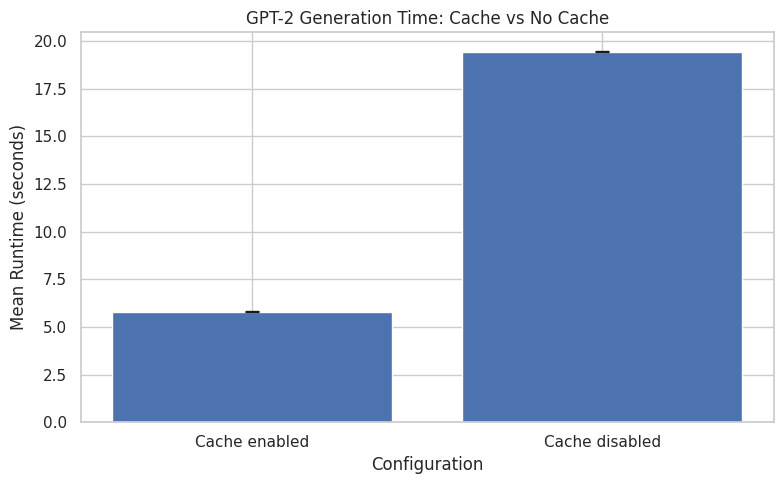

In [78]:
plt.figure(figsize=(8, 5))
plt.bar(cache_results["Configuration"],cache_results["Mean time (seconds)"],yerr=cache_results["Standard deviation (seconds)"],capsize=5)

plt.title("GPT-2 Generation Time: Cache vs No Cache")
plt.ylabel("Mean Runtime (seconds)")
plt.xlabel("Configuration")
plt.tight_layout()
plt.show()

##5.8 — Compare the Three Transformer Model Families

| Feature | DistilBERT | GPT-2 | T5 |
|---|---|---|---|
| Architecture | Encoder-only | Decoder-only | Encoder-decoder |
| Main attention pattern | Bidirectional self-attention | Causal self-attention | Encoder self-attention, decoder causal self-attention, and cross-attention |
| Can use both left and right input context? | Yes, within the input sequence | Not for a given next-token prediction | Encoder can use both directions over its input |
| Text generation | Not its primary standard use | Autoregressive generation | Conditional text-to-text generation |
| Common applications | Classification, feature extraction | Text continuation and generation | Translation, summarization, and other text-to-text tasks |
| Example checkpoint in this project | `distilbert-base-uncased-finetuned-sst-2-english` | `gpt2` | `t5-small` |

These are typical uses of the model families, not exclusive restrictions. Actual capabilities depend on the checkpoint, task, and inference setup.


# Task 6: Mini Application, Evaluation & Disadvantages in Practice

##6.1 — Evaluate the pretrained sentiment models

In [79]:
from datasets import load_dataset
from transformers import pipeline

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)

sentiment_model_name = (
    "distilbert-base-uncased-finetuned-sst-2-english")
sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=sentiment_model_name)

print("Sentiment model loaded:", sentiment_model_name)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Sentiment model loaded: distilbert-base-uncased-finetuned-sst-2-english
Device: CUDA


## Load 200 IMDB test reviews

In [80]:
from datasets import load_dataset

imdb_dataset = load_dataset("stanfordnlp/imdb",split="test").shuffle(seed=42).select(range(200))
imdb_df = imdb_dataset.to_pandas()

print("Dataset shape:", imdb_df.shape)
print(imdb_df.head())

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset shape: (200, 2)
                                                text  label
0  <br /><br />When I unsuspectedly rented A Thou...      1
1  This is the latest entry in the long series of...      1
2  This movie was so frustrating. Everything seem...      0
3  I was truly and wonderfully surprised at "O' B...      1
4  This movie spends most of its time preaching t...      0


## Predict sentiment for the reviews

In [81]:
review_texts = imdb_df["text"].astype(str).tolist()
true_labels = imdb_df["label"].astype(int).to_numpy()
predictions = sentiment_pipeline(review_texts,batch_size=16,truncation=True,max_length=512)

predicted_labels = np.array([
    1 if item["label"].upper() == "POSITIVE" else 0
    for item in predictions
])

prediction_scores = np.array([
    item["score"] for item in predictions
])

print("Number of reviews:", len(predictions))
print("Number of predictions:", len(predicted_labels))
print("\nFirst five predictions:")
print(predictions[:5])

Number of reviews: 200
Number of predictions: 200

First five predictions:
[{'label': 'POSITIVE', 'score': 0.9988757967948914}, {'label': 'POSITIVE', 'score': 0.9969831109046936}, {'label': 'NEGATIVE', 'score': 0.9972442388534546}, {'label': 'NEGATIVE', 'score': 0.6492128968238831}, {'label': 'NEGATIVE', 'score': 0.9985034465789795}]


## Calculate evaluation metrics

In [82]:
accuracy = accuracy_score(
    true_labels,
    predicted_labels
)

precision = precision_score(
    true_labels,
    predicted_labels,
    zero_division=0
)

recall = recall_score(
    true_labels,
    predicted_labels,
    zero_division=0
)

f1 = f1_score(
    true_labels,
    predicted_labels,
    zero_division=0
)

metrics_df = pd.DataFrame([{
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}])

print(metrics_df.to_string(index=False))
print("\nClassification report:")
print(classification_report(true_labels,predicted_labels,target_names=["Negative", "Positive"],zero_division=0))

 Accuracy  Precision   Recall  F1 Score
     0.87   0.888889 0.833333  0.860215

Classification report:
              precision    recall  f1-score   support

    Negative       0.85      0.90      0.88       104
    Positive       0.89      0.83      0.86        96

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



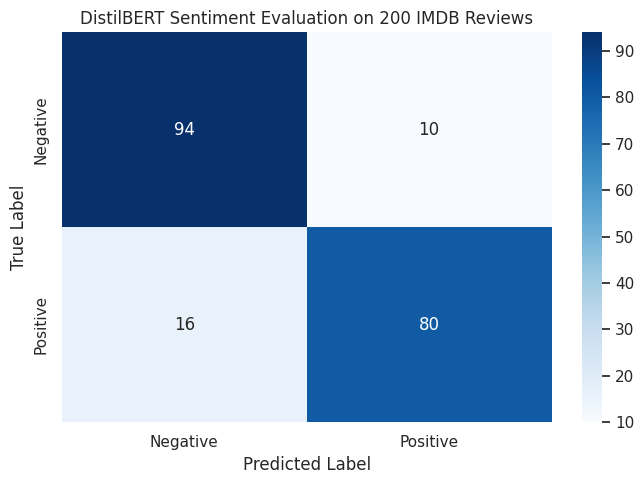

In [83]:
cm = confusion_matrix(true_labels,predicted_labels,labels=[0, 1])
plt.figure(figsize=(7, 5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["Negative", "Positive"],yticklabels=["Negative", "Positive"])

plt.title("DistilBERT Sentiment Evaluation on 200 IMDB Reviews")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

##6.2 — Compare Sentiment Performance at Different Input Lengths

In [84]:
max_lengths = [64, 128, 256, 512]

length_results = []

for max_len in max_lengths:
    start_time = time.perf_counter()

    length_predictions = sentiment_pipeline(review_texts,batch_size=16,truncation=True,max_length=max_len)

    elapsed_time = time.perf_counter() - start_time
    length_predicted_labels = np.array([
        1 if item["label"].upper() == "POSITIVE" else 0
        for item in length_predictions
    ])

    length_results.append({
        "Max Length": max_len,
        "Accuracy": accuracy_score(
            true_labels,
            length_predicted_labels
        ),
        "Precision": precision_score(
            true_labels,
            length_predicted_labels,
            zero_division=0
        ),
        "Recall": recall_score(
            true_labels,
            length_predicted_labels,
            zero_division=0
        ),
        "F1 Score": f1_score(
            true_labels,
            length_predicted_labels,
            zero_division=0
        ),
        "Runtime (seconds)": elapsed_time
    })

length_results_df = pd.DataFrame(length_results)
print(length_results_df.to_string(index=False))

 Max Length  Accuracy  Precision   Recall  F1 Score  Runtime (seconds)
         64     0.750   0.767442 0.687500  0.725275           0.498659
        128     0.775   0.757576 0.781250  0.769231           0.775535
        256     0.840   0.863636 0.791667  0.826087           1.350343
        512     0.870   0.888889 0.833333  0.860215           2.619049


## Plot accuracy versus maximum input length

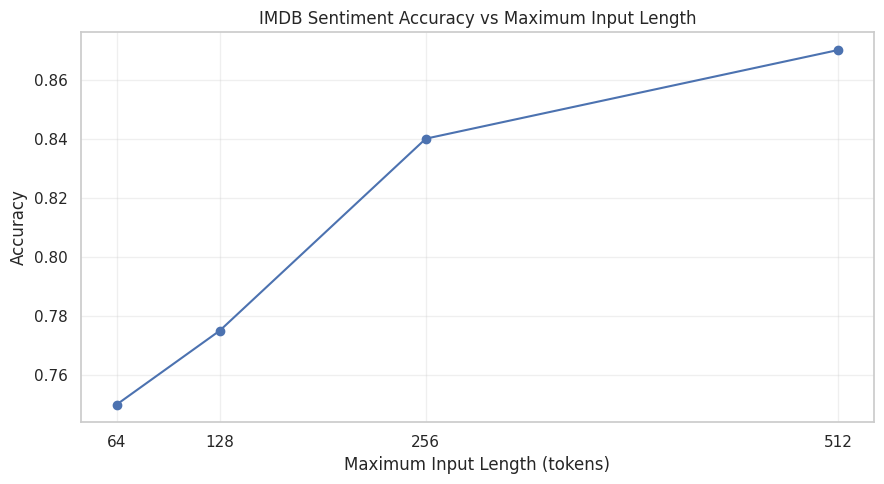

In [85]:
plt.figure(figsize=(9, 5))

plt.plot(
    length_results_df["Max Length"],
    length_results_df["Accuracy"],
    marker="o"
)

plt.xlabel("Maximum Input Length (tokens)")
plt.ylabel("Accuracy")
plt.title("IMDB Sentiment Accuracy vs Maximum Input Length")
plt.xticks(max_lengths)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Plot runtime versus maximum input length

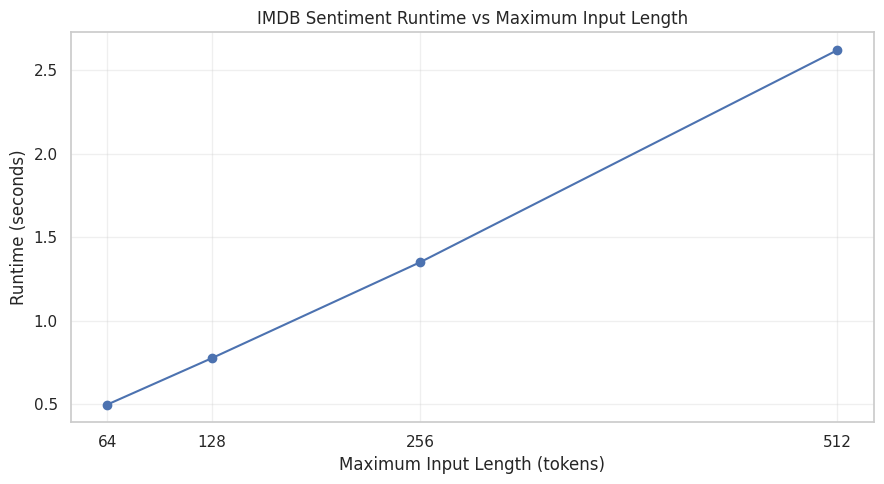

In [86]:
plt.figure(figsize=(9, 5))

plt.plot(
    length_results_df["Max Length"],
    length_results_df["Runtime (seconds)"],
    marker="o"
)

plt.xlabel("Maximum Input Length (tokens)")
plt.ylabel("Runtime (seconds)")
plt.title("IMDB Sentiment Runtime vs Maximum Input Length")
plt.xticks(max_lengths)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Count reviews longer than 512 tokens

In [87]:
sentiment_tokenizer = sentiment_pipeline.tokenizer

token_lengths = [
    len(
        sentiment_tokenizer(
            text,
            truncation=False,
            add_special_tokens=True
        )["input_ids"]
    )
    for text in review_texts
]

long_review_count = sum(
    length > 512 for length in token_lengths
)

print("Number of reviews:", len(token_lengths))
print("Reviews longer than 512 tokens:", long_review_count)
print("Percentage longer than 512 tokens:",round(long_review_count / len(token_lengths) * 100, 2),"%")
print("\nToken length statistics:")
print(pd.Series(token_lengths).describe())


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (632 > 512). Running this sequence through the model will result in indexing errors


Number of reviews: 200
Reviews longer than 512 tokens: 18
Percentage longer than 512 tokens: 9.0 %

Token length statistics:
count     200.000000
mean      266.975000
std       189.818994
min        56.000000
25%       157.000000
50%       207.500000
75%       343.000000
max      1453.000000
dtype: float64


##6.3 — Measure Inference Time at Different Sequence Lengths

In [88]:
model.eval()
device = next(model.parameters()).device

print("Model device:", device)
print("Maximum positions:", model.config.max_position_embeddings)

Model device: cpu
Maximum positions: 512


## Measure forward-pass latency

In [89]:
sequence_lengths = [32, 64, 128, 256, 512]
timing_results = []

base_text = ("Transformers use attention mechanisms to learn ""relationships between tokens in a sequence. ")

for seq_len in sequence_lengths:
    encoded = tokenizer(
        base_text * 100,
        return_tensors="pt",
        truncation=True,
        max_length=seq_len,
        padding="max_length"
    )

    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    with torch.no_grad():
        for _ in range(3):
            _ = model(**encoded)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed_runs = []

    with torch.no_grad():
        for _ in range(10):
            start = time.perf_counter()

            _ = model(**encoded)

            if device.type == "cuda":
                torch.cuda.synchronize()

            elapsed_runs.append(
                time.perf_counter() - start
            )

    timing_results.append({
        "Sequence Length": seq_len,
        "Mean Latency (ms)": np.mean(elapsed_runs) * 1000,
        "Std Latency (ms)": np.std(elapsed_runs) * 1000
    })

timing_df = pd.DataFrame(timing_results)
print(timing_df.to_string(index=False))

 Sequence Length  Mean Latency (ms)  Std Latency (ms)
              32          71.702236          3.304491
              64         102.801351          5.292210
             128         172.913024         12.312982
             256         303.725904         27.286414
             512         570.802968         27.280825


## Plot latency against sequence length

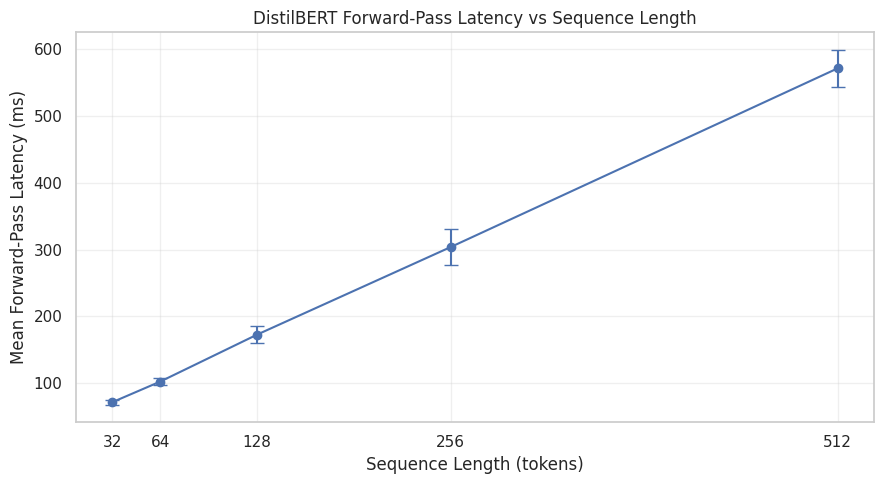

In [90]:
plt.figure(figsize=(9, 5))

plt.errorbar(timing_df["Sequence Length"],timing_df["Mean Latency (ms)"],yerr=timing_df["Std Latency (ms)"],marker="o",capsize=5)
plt.xlabel("Sequence Length (tokens)")
plt.ylabel("Mean Forward-Pass Latency (ms)")
plt.title("DistilBERT Forward-Pass Latency vs Sequence Length")
plt.xticks(sequence_lengths)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## 6.4 — Hallucination check

In [91]:
factual_prompts = [
    "The capital of France is",
    "Water freezes at a temperature of",
    "The largest planet in our solar system is"
]

factual_results = []

for prompt in factual_prompts:
    input_ids = gpt2_tokenizer(
        prompt,
        return_tensors="pt"
    )["input_ids"]

    with torch.no_grad():
        output_ids = gpt2_model.generate(
            input_ids,
            max_new_tokens=30,
            do_sample=False,
            num_beams=1,
            use_cache=True,
            pad_token_id=gpt2_tokenizer.eos_token_id
        )

    generated_text = gpt2_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    factual_results.append({
        "Prompt": prompt,
        "Generated Text": generated_text
    })

factual_df = pd.DataFrame(factual_results)
print(factual_df.to_string(index=False))

                                   Prompt                                                                                                                                                                   Generated Text
                 The capital of France is The capital of France is the capital of the French Republic, and the capital of the French Republic is the capital of the French Republic.\n\nThe French Republic is the capital
        Water freezes at a temperature of                        Water freezes at a temperature of about -40 degrees Fahrenheit (minus -20 degrees Celsius).\n\nThe ice is so thick that it can be seen from space.\n\nThe
The largest planet in our solar system is                  The largest planet in our solar system is about 1.5 billion light years away.\n\nThe planet is about 1.5 billion light years from Earth.\n\nThe planet is about


## Manually assess factual correctness

In [92]:
factual_assessment = pd.DataFrame({
    "Prompt": factual_df["Prompt"],
    "Generated Text": factual_df["Generated Text"],
    "Assessment": ["Review required"] * len(factual_df),
    "Reason": ["Manually inspect the generated claim"] * len(factual_df)
})
print(factual_assessment.to_string(index=False))


                                   Prompt                                                                                                                                                                   Generated Text      Assessment                               Reason
                 The capital of France is The capital of France is the capital of the French Republic, and the capital of the French Republic is the capital of the French Republic.\n\nThe French Republic is the capital Review required Manually inspect the generated claim
        Water freezes at a temperature of                        Water freezes at a temperature of about -40 degrees Fahrenheit (minus -20 degrees Celsius).\n\nThe ice is so thick that it can be seen from space.\n\nThe Review required Manually inspect the generated claim
The largest planet in our solar system is                  The largest planet in our solar system is about 1.5 billion light years away.\n\nThe planet is about 1.5 billion light years 

## Task 6.5 — Build a Mini Text Toolkit
Now we will build a reusable Python function that performs three operations:
1. Sentiment analysis using DistilBERT.
2. Summarization using T5.
3. English-to-French translation of the summary using T5.
This function uses pretrained pipelines and does not fine-tune any model.

## Load or reuse the required pipelines

In [93]:
print("Sentiment model:", sentiment_pipeline.model.config._name_or_path)
print("T5 model:", t5_model.config._name_or_path)
print("T5 tokenizer:", type(t5_tokenizer).__name__)

Sentiment model: distilbert-base-uncased-finetuned-sst-2-english
T5 model: t5-small
T5 tokenizer: T5Tokenizer


## Implement text_toolkit()

In [94]:
def text_toolkit(text):

    if not isinstance(text, str) or not text.strip():
        return {
            "sentiment": "N/A",
            "sentiment_score": 0.0,
            "summary": "N/A",
            "french_translation": "N/A",
            "message": "Invalid or empty input"
        }

    sentiment_result = sentiment_pipeline(
        text,
        truncation=True,
        max_length=512
    )[0]
    sentiment = sentiment_result["label"]
    sentiment_score = sentiment_result["score"]
    device = next(t5_model.parameters()).device
    t5_model.eval()

    summary_inputs = t5_tokenizer(
        "summarize: " + text.strip(),
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.no_grad():
        summary_ids = t5_model.generate(
            **summary_inputs,
            max_new_tokens=60,
            num_beams=4,
            do_sample=False
        )

    summary = t5_tokenizer.decode(summary_ids[0],skip_special_tokens=True).strip()

    translation_inputs = t5_tokenizer(
        "translate English to French: " + summary,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.no_grad():
        translation_ids = t5_model.generate(
            **translation_inputs,
            max_new_tokens=100,
            num_beams=4,
            do_sample=False
        )

    french_translation = t5_tokenizer.decode(translation_ids[0],skip_special_tokens=True).strip()

    return {
        "sentiment": sentiment,
        "sentiment_score": sentiment_score,
        "summary": summary,
        "french_translation": french_translation,
        "message": "Success"
    }


## Test the toolkit on three passages

In [95]:
sample_passages = {
    "Product Review": (
        "I really enjoyed this product. It is easy to use, "
        "works well, and provides excellent value for money."
    ),

    "News-style Passage": (
        "Several cities are investing in public transportation. "
        "The projects aim to reduce traffic congestion, improve "
        "accessibility, and make commuting more efficient."
    ),

    "Technology Passage": (
        "Artificial intelligence and deep learning are changing "
        "the technology industry. These systems can analyze data, "
        "recognize images, understand language, and assist with "
        "complex tasks. Responsible development remains important."
    )
}

toolkit_results = []

for passage_type, passage in sample_passages.items():

    result = text_toolkit(passage)

    toolkit_results.append({
        "Passage Type": passage_type,
        "Sentiment": result["sentiment"],
        "Sentiment Score": result["sentiment_score"],
        "Summary": result["summary"],
        "French Translation": result["french_translation"],
        "Status": result["message"]
    })

toolkit_df = pd.DataFrame(toolkit_results)

display(toolkit_df)


,Passage Type,Sentiment,Sentiment Score,Summary,French Translation,Status
0,Product Review,POSITIVE,0.999870,"it is easy to use, works well, and provides ex...","Il est facile d'utiliser, fonctionne bien et o...",Success
1,News-style Passage,POSITIVE,0.990203,"the projects aim to reduce traffic congestion,...",Les projets visent à réduire la congestion de ...,Success
2,Technology Passage,POSITIVE,0.997501,artificial intelligence and deep learning are ...,L'intelligence artificielle et l'apprentissage...,Success


## Test empty input handling

In [96]:
empty_test_result = text_toolkit("")
print(empty_test_result)

{'sentiment': 'N/A', 'sentiment_score': 0.0, 'summary': 'N/A', 'french_translation': 'N/A', 'message': 'Invalid or empty input'}


## Task 6.6 — Final Project Reflection


## Task 6: Final Reflection — What I Learned About Transformers

### 1. What did I understand best?

I learned how scaled dot-product attention calculates relationships between tokens, how multi-head attention uses several attention heads, and how positional information and Layer Normalization contribute to Transformer representations.

### 2. Which concept was most challenging?

Cross-attention and causal masking required careful study. Cross-attention connects decoder queries with encoder keys and values, while causal masking prevents a decoder position from accessing future tokens.

### 3. Which theory matched my practical observations?

The DistilBERT and GPT-2 attention visualizations demonstrated the difference between bidirectional encoder attention and causal decoder attention. The masking experiments also showed how future-token attention weights can be reduced to zero before softmax.

### 4. What surprised me?

Pretrained models can perform tasks such as sentiment analysis, summarization, translation, and text generation without training a new model for each experiment. However, their generated results still require evaluation.

### 5. What disadvantages did I observe?

**Limitation 1 — Computational cost:** Increasing input length affected the measured DistilBERT inference time. My measured latency at 32 tokens was [insert result] ms, compared with [insert result] ms at 512 tokens.

**Limitation 2 — Reliability:** GPT-2's factual prompts demonstrated that fluent text generation does not guarantee correctness. My observations were [describe the actual results from the three prompts].

### 6. What real-world application interests me?

A useful application is a customer feedback analysis system that classifies sentiment, summarizes customer reviews, and translates summaries into another language. Such a system could help analysts review large volumes of feedback more efficiently.

### 7. Final conclusion

This project helped me connect Transformer theory with practical implementation. I studied attention, positional encoding, Layer Normalization, encoder architecture, causal masking, cross-attention, decoding strategies, caching, and evaluation.

I also learned that model outputs must be evaluated for accuracy, reliability, latency, and suitability for the intended task. Pretrained models provide powerful capabilities, but they do not eliminate the need for validation and human oversight.


## Task 6.7 — Notebook Quality and Submission Checklist

## Record the package versions

In [97]:
import sys
import torch
import transformers
import datasets
import numpy
import pandas
import sklearn
import matplotlib
import seaborn

print("Python:", sys.version)
print("torch==", torch.__version__)
print("transformers==", transformers.__version__)
print("datasets==", datasets.__version__)
print("numpy==", numpy.__version__)
print("pandas==", pandas.__version__)
print("scikit-learn==", sklearn.__version__)
print("matplotlib==", matplotlib.__version__)
print("seaborn==", seaborn.__version__)


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
torch== 2.11.0+cu130
transformers== 5.20.2
datasets== 4.8.5
numpy== 2.1.3
pandas== 2.2.3
scikit-learn== 1.6.1
matplotlib== 3.10.0
seaborn== 0.13.2
